In [1]:
# Renderizar PNGs sem abrir janelas de GUI no Windows.
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
import random
import numpy as np
import torch

# Rede pequena em CPU: limitar threads evita sobrecarga de paralelismo.
torch.set_num_threads(1)
SEMENTE = 42

def fixar_semente(semente):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.use_deterministic_algorithms(True)

def mostrar_e_fechar(fig):
    """Renderiza uma imagem estática e libera a figura, mesmo se houver erro."""
    try:
        with BytesIO() as buffer:
            fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
            display(Image(data=buffer.getvalue(), format="png"))
    finally:
        plt.close(fig)

fixar_semente(SEMENTE)

from pathlib import Path
import sys
import pandas as pd

from sklearn.model_selection import train_test_split

# Raiz do repositório: sobe a partir da pasta atual até achar o mkdocs.yml,
# para o notebook rodar tanto da raiz quanto de docs/projects/classification/code/
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mkdocs.yml").exists())
EDA_CODE = BASE / "docs" / "projects" / "eda" / "code"
DATA_PATH = BASE / "docs" / "projects" / "eda" / "data" / "healthcare-dataset-stroke-data.csv"

sys.path.insert(0, str(EDA_CODE))
from preprocessing import build_preprocessor, balance_training, NUM, CAT, TARGET

df = pd.read_csv(DATA_PATH)

X = df[NUM + CAT].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (4088, 10)
Teste: (1022, 10)


In [2]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Treino:", X_train_sub.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

print("\nProporção de AVC:")
print("Treino:", round(y_train_sub.mean() * 100, 2), "%")
print("Validação:", round(y_val.mean() * 100, 2), "%")
print("Teste:", round(y_test.mean() * 100, 2), "%")

Treino: (3270, 10)
Validação: (818, 10)
Teste: (1022, 10)

Proporção de AVC:
Treino: 4.86 %
Validação: 4.89 %
Teste: 4.89 %


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

baselines = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Logística balanceada": LogisticRegression(max_iter=1000, random_state=42,
                                               class_weight="balanced"),
}

resultados = {}
for nome, clf in baselines.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    pipe.fit(X_train_sub, y_train_sub)
    proba = pipe.predict_proba(X_val)[:, 1]
    resultados[nome] = {
        "PR-AUC": average_precision_score(y_val, proba),
        "ROC-AUC": roc_auc_score(y_val, proba),
        "proba": proba,
        "modelo": pipe,
    }
    print(f"{nome:22s} PR-AUC={resultados[nome]['PR-AUC']:.3f}  "
          f"ROC-AUC={resultados[nome]['ROC-AUC']:.3f}")

Dummy                  PR-AUC=0.049  ROC-AUC=0.500
Logística              PR-AUC=0.233  ROC-AUC=0.846
Logística balanceada   PR-AUC=0.212  ROC-AUC=0.842


### Métrica principal e critério de sucesso

**Métrica principal: PR-AUC (Average Precision).** O dataset é fortemente desbalanceado: cerca de 4,87% dos registros são pacientes com AVC. Nesse cenário a acurácia não serve, porque o Dummy, que nunca prevê AVC, atinge 95,1% de acurácia com recall 0.

A PR-AUC também é preferível à ROC-AUC. Na validação, a Regressão Logística tem **ROC-AUC de 0,846**, mas **PR-AUC de só 0,233**. A ROC-AUC usa a taxa de falsos positivos, cujo denominador são os 778 negativos, então muitos alarmes falsos ainda parecem uma taxa pequena. A PR-AUC usa a precisão, que compara esses alarmes falsos com os 40 positivos reais e mostra o quanto o modelo ainda erra na classe que importa. O piso da PR-AUC é a prevalência (0,049, a PR-AUC do Dummy); o da ROC-AUC é 0,5.

Precisão, F1 e ROC-AUC são acompanhados como métricas complementares.

**Análise individual do recall.** Neste problema os dois erros não custam o mesmo. Um falso negativo é um paciente com AVC que o modelo deixa passar, e isso pode atrasar um atendimento urgente. Um falso positivo é um alarme falso, que leva a exames adicionais. Por isso o recall da classe AVC é analisado à parte e tem prioridade na escolha do limiar de decisão: o objetivo é deixar passar o menor número possível de casos de AVC, aceitando a queda de precisão (mais alarmes falsos) que isso causa.

**Critério de sucesso (definido antes de treinar a rede):** a MLP é considerada bem-sucedida se sua **PR-AUC no teste, em média de 3 sementes, for pelo menos 10% maior que a da melhor Regressão Logística no teste**. Com o valor de validação como referência (0,233), isso equivale a uma PR-AUC de cerca de 0,256. A meta de 10%, e não maior, leva em conta que o teste tem apenas 50 positivos: com tão poucos casos, a PR-AUC varia alguns pontos entre divisões, e uma meta mais alta dependeria mais do acaso do que do modelo.


In [4]:
preprocess = build_preprocessor()

X_train_sub_t = preprocess.fit_transform(X_train_sub)
X_val_t = preprocess.transform(X_val)

print("Treino:", X_train_sub_t.shape)
print("Validação:", X_val_t.shape)

Treino: (3270, 24)
Validação: (818, 24)


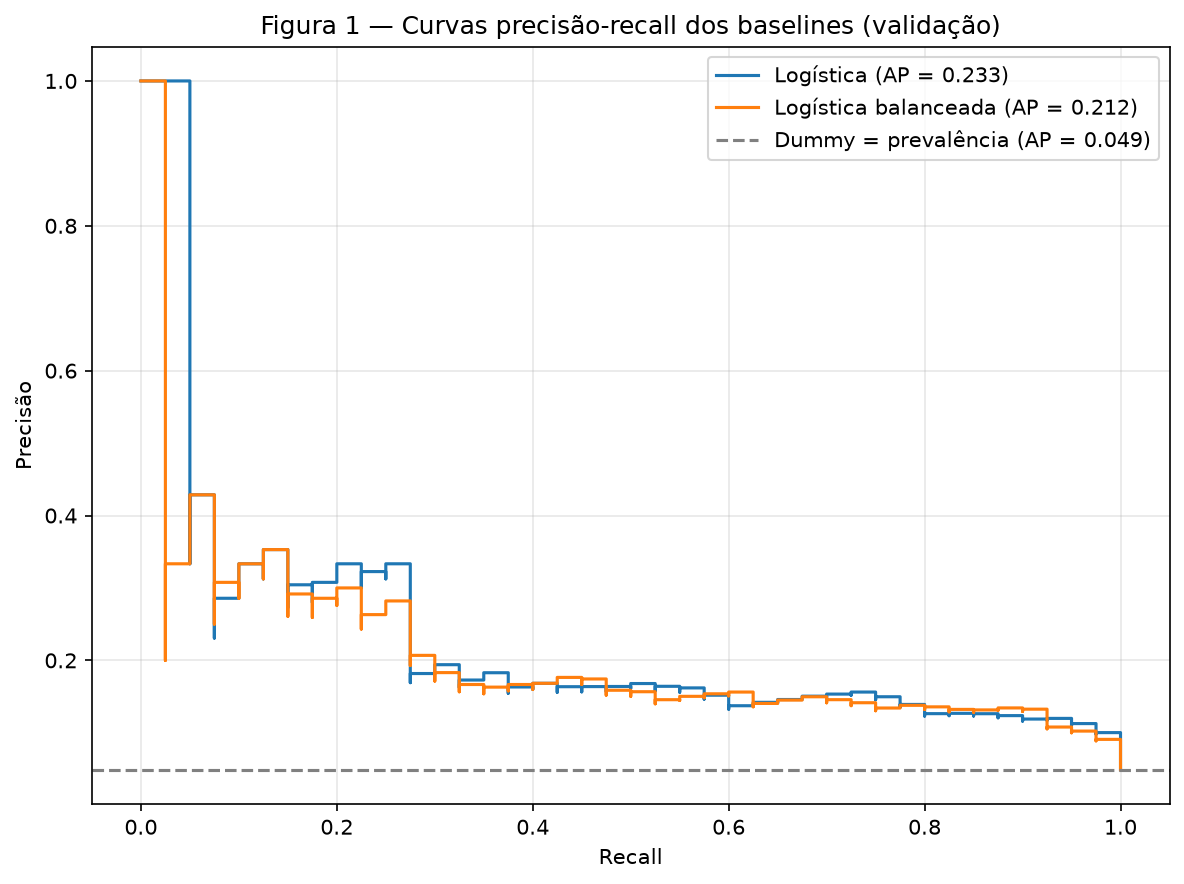

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))
for nome, r in resultados.items():
    if nome == "Dummy":
        continue  # nota constante: sua "curva" é só a linha da prevalência, desenhada abaixo
    p, rc, _ = precision_recall_curve(y_val, r["proba"])
    plt.plot(rc, p, drawstyle="steps-post", label=f"{nome} (AP = {r['PR-AUC']:.3f})")
plt.axhline(y_val.mean(), linestyle="--", color="gray",
            label=f"Dummy = prevalência (AP = {resultados['Dummy']['PR-AUC']:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Figura 1 — Curvas precisão-recall dos baselines (validação)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

FIGURES = BASE / "docs" / "projects" / "classification" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES / "fig01-baselines-pr.png", dpi=150, bbox_inches="tight")
mostrar_e_fechar(plt.gcf())


In [6]:
# Tabela 1 — Logística comum × balanceada
comum, bal = resultados["Logística"], resultados["Logística balanceada"]

def marcados_e_casos(proba, limiar):
    marcados = proba >= limiar
    return int(marcados.sum()), int((marcados & (y_val.to_numpy() == 1)).sum())

tabela1 = pd.DataFrame({
    "Comum": [
        comum["modelo"][-1].intercept_[0],
        comum["proba"].mean(),
        comum["PR-AUC"],
        "%d / %d" % marcados_e_casos(comum["proba"], 0.5),
        "%d / %d" % marcados_e_casos(comum["proba"], 0.05),
    ],
    "Balanceada": [
        bal["modelo"][-1].intercept_[0],
        bal["proba"].mean(),
        bal["PR-AUC"],
        "%d / %d" % marcados_e_casos(bal["proba"], 0.5),
        "—",
    ],
}, index=[
    "Intercepto b (treino)",
    "Nota média",
    "PR-AUC",
    "Limiar 0,5: marcados / casos pegos",
    "Limiar 0,05: marcados / casos pegos",
])
tabela1


,Comum,Balanceada
Intercepto b (treino),-3.827545,-0.254899
Nota média,0.046193,0.311599
PR-AUC,0.233303,0.211704
"Limiar 0,5: marcados / casos pegos",3 / 2,223 / 30
"Limiar 0,05: marcados / casos pegos",230 / 32,—


### Por que balancear a Logística não melhorou a PR-AUC

A Logística balanceada (`class_weight="balanced"`) multiplica o erro de cada paciente com AVC por ≈ 10,3 e o de cada paciente sem AVC por ≈ 0,53. Assim, as duas classes pesam igualmente na perda: para o modelo, é como se o treino tivesse 50% de AVC. Ainda assim, sua PR-AUC na validação (0,212) não superou a da Logística comum (0,233).

A Tabela 1 mostra o motivo. O intercepto `b` é o termo constante somado à nota de todos os pacientes. No treino, ele é ajustado até que a média ponderada de (nota − rótulo real) seja zero, ou seja, até a nota média coincidir com a frequência de AVC que o modelo enxerga: 4,9% na comum e 50% na balanceada. Por isso o intercepto subiu de −3,83 para −0,25 e a nota média na validação passou de 0,046 para 0,312.

**Tabela 1 — Logística comum × balanceada (validação, exceto o intercepto).**

| | Comum | Balanceada |
|---|---|---|
| Intercepto `b` (treino) | −3,83 | −0,25 |
| Nota média | 0,046 | 0,312 |
| PR-AUC | 0,233 | 0,212 |
| Limiar 0,5: marcados / casos pegos | 3 / 2 | 223 / 30 |
| Limiar 0,05: marcados / casos pegos | 230 / 32 | — |

No limiar 0,5, a balanceada marca 223 pacientes e identifica 30 dos 40 casos. A comum obtém resultado equivalente (230 marcados, 32 casos) apenas baixando o limiar para 0,05. Em um modelo linear, portanto, ponderar as classes equivale a mover o limiar e não acrescenta capacidade de separar os casos. Isso reforça a separação adotada na etapa 0: a PR-AUC escolhe o modelo, e o limiar é definido depois, pelo custo dos erros.


In [7]:
y_val_pred_lr = resultados["Logística"]["modelo"].predict(X_val)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Precision:", precision_score(y_val, y_val_pred_lr, zero_division=0))
print("Recall:", recall_score(y_val, y_val_pred_lr, zero_division=0))
print("F1-score:", f1_score(y_val, y_val_pred_lr, zero_division=0))

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_val_pred_lr))

Precision: 0.6666666666666666
Recall: 0.05
F1-score: 0.09302325581395349

Matriz de confusão:
[[777   1]
 [ 38   2]]


In [8]:
import torch

# Converter características
X_train_tensor = torch.tensor(
    X_train_sub_t,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_t,
    dtype=torch.float32
)

# Converter rótulos
y_train_tensor = torch.tensor(
    y_train_sub.to_numpy(),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
)

In [9]:
print("X treino:", X_train_tensor.shape)
print("y treino:", y_train_tensor.shape)

print("X validação:", X_val_tensor.shape)
print("y validação:", y_val_tensor.shape)

X treino: torch.Size([3270, 24])
y treino: torch.Size([3270])
X validação: torch.Size([818, 24])
y validação: torch.Size([818])


### Escolha da arquitetura pela validação

O teorema da aproximação universal garante que uma camada oculta com ativação não linear é suficiente em princípio, mas não diz quantos neurônios usar. Por isso, antes de definir a rede, a largura é escolhida empiricamente: mantendo uma camada oculta com ReLU, três larguras são comparadas — 16 (ponto de partida, entre o número de variáveis originais, 11, e o de colunas de entrada, 24), 8 (a metade) e 32 (o dobro). Cada uma é treinada com AdamW (lr = 0,001, weight decay = 0), batch 32, até 100 épocas e parada antecipada pela perda de validação (paciência 10, com restauração dos melhores pesos), com 5 sementes. Adotamos AdamW para manter o mesmo otimizador na comparação posterior de regularização; nesta etapa, weight decay igual a zero define a referência sem essa penalização. A comparação usa a PR-AUC média na validação, e a rede definida em seguida usa a largura vencedora.

Na notação da aula, uma camada com `W ∈ ℝ^(m×n)` tem `m·n + m` parâmetros; para uma camada oculta de largura `m` e 24 entradas, a rede tem `24m + m + m + 1 = 26m + 1` parâmetros.


In [10]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import average_precision_score


def construir_mlp(ocultas, n_entradas=24, vies_saida=None):
    """MLP com ReLU; `ocultas` é a lista de larguras, ex.: (16, 8).
    `vies_saida`: valor inicial do viés do neurônio de saída (None = padrão do PyTorch)."""
    camadas, k = [], n_entradas
    for largura in ocultas:
        camadas += [nn.Linear(k, largura), nn.ReLU()]
        k = largura
    camadas.append(nn.Linear(k, 1))  # 1 logit
    if vies_saida is not None:
        nn.init.constant_(camadas[-1].bias, vies_saida)
    return nn.Sequential(*camadas)


def treinar_e_avaliar(ocultas, semente, max_epocas=100, paciencia=10, vies_saida=None):
    """Treina com parada antecipada e devolve (PR-AUC na validação, melhor época)."""
    fixar_semente(semente)
    modelo = construir_mlp(ocultas, vies_saida=vies_saida)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001, weight_decay=0.0)
    perda_fn = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor),
                        batch_size=32, shuffle=True)

    melhor_perda, melhores_pesos, melhor_epoca, sem_melhora = float("inf"), None, 0, 0
    for epoca in range(1, max_epocas + 1):
        modelo.train()
        for xb, yb in loader:
            perda = perda_fn(modelo(xb).squeeze(1), yb)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()

        modelo.eval()
        with torch.no_grad():
            perda_val = perda_fn(modelo(X_val_tensor).squeeze(1), y_val_tensor).item()
        if perda_val < melhor_perda:
            melhor_perda, melhor_epoca, sem_melhora = perda_val, epoca, 0
            melhores_pesos = copy.deepcopy(modelo.state_dict())
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break

    modelo.load_state_dict(melhores_pesos)
    with torch.no_grad():
        proba = torch.sigmoid(modelo(X_val_tensor).squeeze(1)).numpy()
    return average_precision_score(y_val, proba), melhor_epoca


arquiteturas = [(8,), (16,), (32,)]
sementes = range(5)
n_avc_treino = int(y_train_sub.sum())

linhas = []
for ocultas in arquiteturas:
    res = [treinar_e_avaliar(ocultas, s) for s in sementes]
    pr = np.array([r[0] for r in res])
    n_params = sum(p.numel() for p in construir_mlp(ocultas).parameters())
    linhas.append({
        "arquitetura": "-".join(map(str, (24, *ocultas, 1))),
        "camadas ocultas": len(ocultas),
        "parâmetros": n_params,
        "parâmetros por AVC": n_params / n_avc_treino,
        "PR-AUC média": pr.mean(),
        "desvio": pr.std(),
        "melhor época média": np.mean([r[1] for r in res]),
    })

tabela_arquiteturas = (pd.DataFrame(linhas)
                       .sort_values("PR-AUC média", ascending=False)
                       .reset_index(drop=True))
tabela_arquiteturas.round(3)


,arquitetura,camadas ocultas,parâmetros,parâmetros por AVC,PR-AUC média,desvio,melhor época média
0,24-8-1,1,209,1.314,0.225,0.008,28.8
1,24-16-1,1,417,2.623,0.212,0.009,17.8
2,24-32-1,1,833,5.239,0.207,0.008,14.2


**Leitura da tabela.** A largura 8 (209 parâmetros, ≈ 1,3 por caso de AVC no treino) obteve a maior PR-AUC média, 0,225 ± 0,008, contra 0,212 ± 0,009 da largura 16 e 0,207 ± 0,008 da largura 32. Dobrar a largura antecipa a melhor época (de cerca de 29 para 18 e 14 épocas) e reduz a PR-AUC, sinal de que a rede passa a memorizar os 159 casos de AVC do treino. As diferenças são da ordem de 1 a 2 desvios entre sementes: indicam uma tendência, não uma separação forte. Nenhuma largura superou a Regressão Logística (PR-AUC 0,233) nesta configuração, ainda sem tratamento do desbalanceamento e sem regularização.


In [11]:
# Teste do viés inicial da saída: padrão do PyTorch × log-odds da prevalência
import math

prevalencia_treino = float(y_train_sub.mean())
log_odds = math.log(prevalencia_treino / (1 - prevalencia_treino))
print(f"Prevalência de AVC no treino: {prevalencia_treino:.4f} -> log-odds = {log_odds:.3f}")

perda_fn = nn.BCEWithLogitsLoss()
linhas = []
for nome, vies in [("padrão do PyTorch", None), (f"log-odds ({log_odds:.2f})", log_odds)]:
    iniciais, resultados_vies = [], []
    for s in sementes:
        fixar_semente(s)
        m = construir_mlp((8,), vies_saida=vies)
        with torch.no_grad():
            logits = m(X_train_tensor).squeeze(1)
            iniciais.append((torch.sigmoid(logits).mean().item(),
                             perda_fn(logits, y_train_tensor).item()))
        resultados_vies.append(treinar_e_avaliar((8,), s, vies_saida=vies))
    pr = np.array([r[0] for r in resultados_vies])
    linhas.append({
        "viés inicial da saída": nome,
        "P(AVC) média antes do treino": np.mean([x[0] for x in iniciais]),
        "perda inicial (treino)": np.mean([x[1] for x in iniciais]),
        "melhor época média": np.mean([r[1] for r in resultados_vies]),
        "PR-AUC média": pr.mean(),
        "desvio": pr.std(),
    })

tabela_vies = pd.DataFrame(linhas)
tabela_vies.round(3)


Prevalência de AVC no treino: 0.0486 -> log-odds = -2.974


,viés inicial da saída,P(AVC) média antes do treino,perda inicial (treino),melhor época média,PR-AUC média,desvio
0,padrão do PyTorch,0.534,0.763,28.8,0.225,0.008
1,log-odds (-2.97),0.050,0.196,26.4,0.222,0.015


### Ativação e inicialização

**Ativação: ReLU** nos neurônios ocultos. Sem uma ativação não linear, duas camadas lineares se reduzem a uma só (`V(W·x) = (VW)·x`) e a rede seria equivalente à Regressão Logística. A ReLU (`max(0, x)`) treina mais rápido e reduz o gradiente desvanecente, pois sua derivada vale 1 onde o neurônio está ativo, enquanto a da sigmoide nunca passa de 0,25. Na saída não há ativação na rede: ela devolve o logit, e a sigmoide fica dentro da `BCEWithLogitsLoss`.

**Pesos: inicialização padrão do PyTorch.** Os pesos são sorteados (uniformes em ±1/√n_entradas), o que quebra a simetria entre os neurônios — se começassem iguais, receberiam os mesmos gradientes e continuariam iguais, desperdiçando a largura — e mantém uma escala adequada para uma rede de uma camada oculta.

**Viés da saída: log-odds da prevalência.** O viés do neurônio de saída é somado igualmente à nota de todos os pacientes, como o intercepto da Regressão Logística. Com o sorteio padrão, a rede começa prevendo cerca de 50% de AVC para todos, embora a frequência no treino seja 4,9%. Por isso o viés é iniciado em log(p / (1 − p)) ≈ −2,97, calculado com a prevalência do treino: a rede já começa prevendo ≈ 5% e a perda inicial cai de ≈ 0,76 para ≈ 0,20 (tabela acima). O efeito fica restrito ao início do treino: a melhor época e a PR-AUC na validação não mudam além do ruído entre sementes. A escolha foi mantida por coerência com o desbalanceamento do dataset e com o comportamento do intercepto observado na Regressão Logística.


In [12]:
import math
import torch.nn as nn

class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        # Largura 8: maior PR-AUC média na validação entre 8, 16 e 32 (tabela acima)
        self.hidden = nn.Linear(24, 8)
        self.relu = nn.ReLU()
        self.output = nn.Linear(8, 1)

        # Viés da saída iniciado no log-odds da prevalência de AVC no treino (≈ −2,97)
        p = float(y_train_sub.mean())
        nn.init.constant_(self.output.bias, math.log(p / (1 - p)))

    def forward(self, x):
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)

        return x

In [13]:
fixar_semente(SEMENTE)
modelo_mlp = MLP()

print(modelo_mlp)

MLP(
  (hidden): Linear(in_features=24, out_features=8, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=8, out_features=1, bias=True)
)


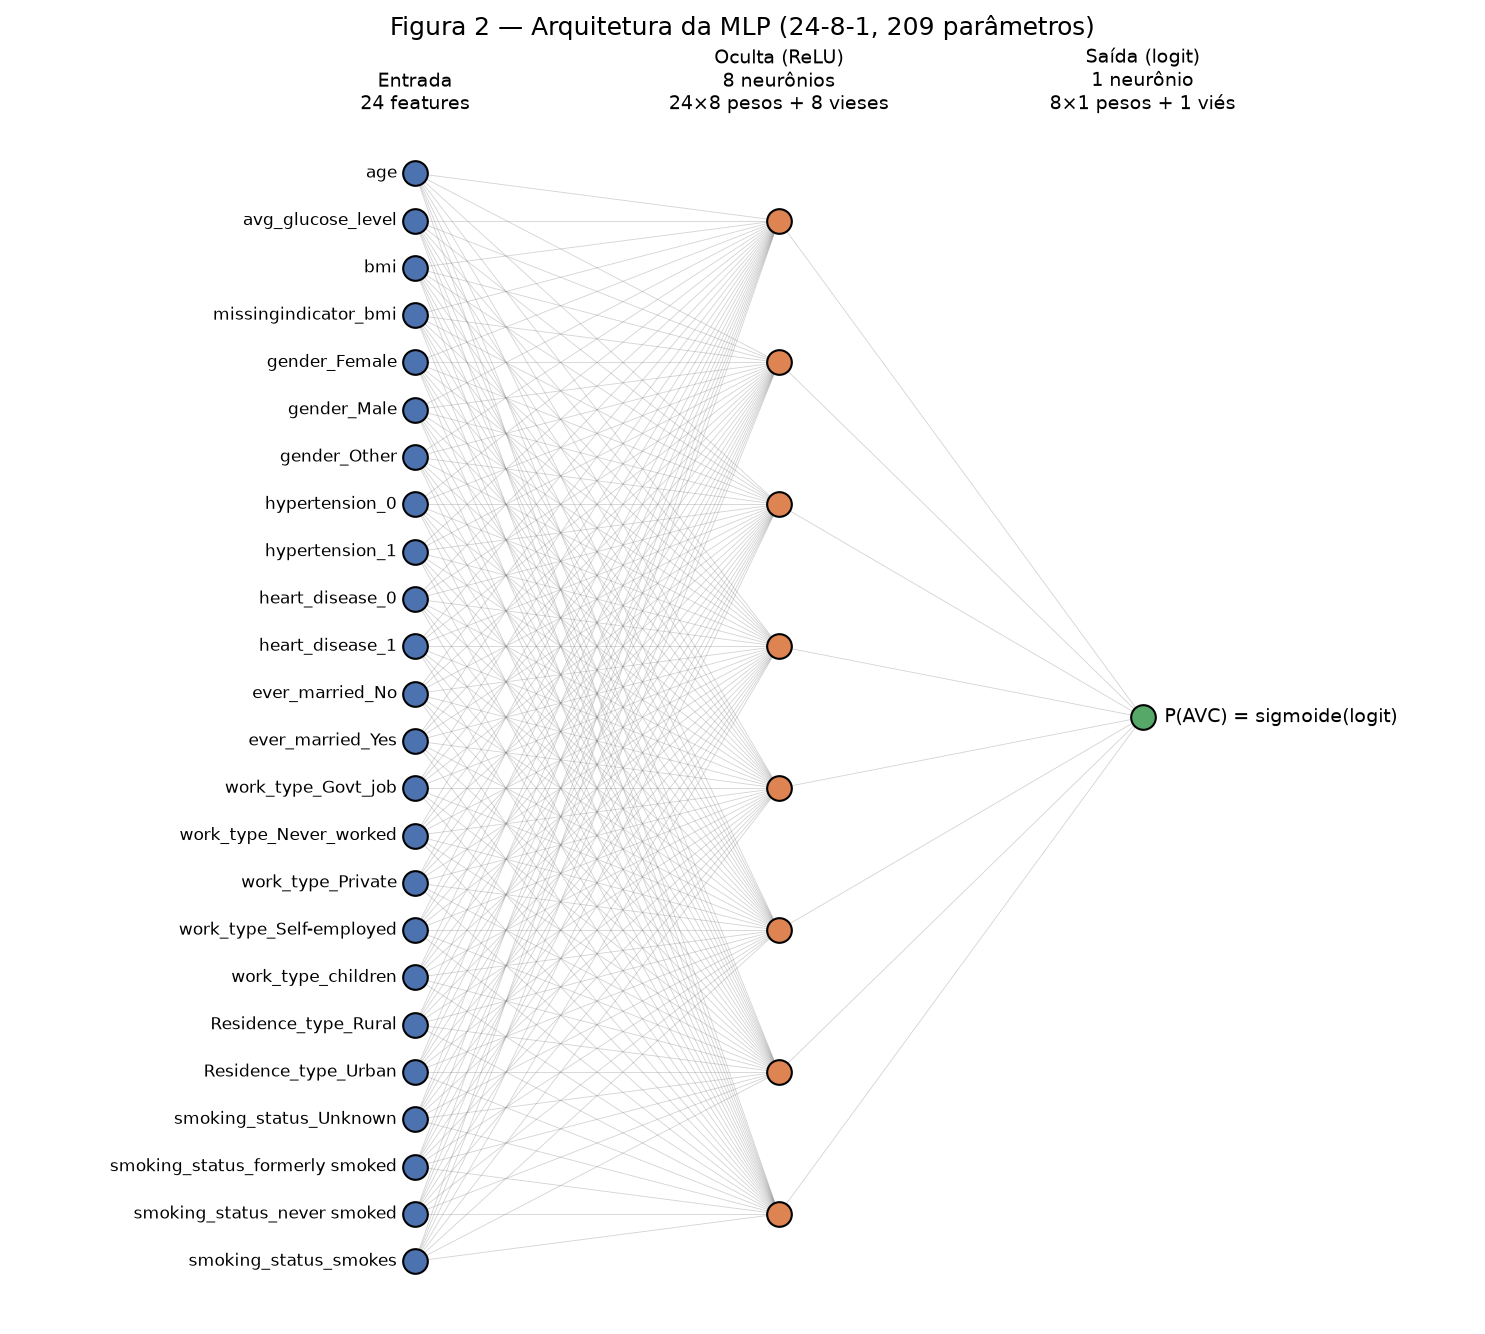

In [14]:
# Figura 2 — grafo da MLP (tamanhos lidos do próprio modelo)
import matplotlib.pyplot as plt

camadas_lin = [m for m in modelo_mlp.modules() if isinstance(m, nn.Linear)]
tamanhos = [camadas_lin[0].in_features] + [m.out_features for m in camadas_lin]
nomes_entrada = [n.split("__", 1)[1] for n in preprocess.get_feature_names_out()]
rotulos_camada = ["Entrada", "Oculta (ReLU)", "Saída (logit)"]

fig, ax = plt.subplots(figsize=(10, 9))
xs = [0.0, 1.0, 2.0]
pos = []
for x, n in zip(xs, tamanhos):
    ys = [1 - (k + 0.5) / n for k in range(n)] if n > 1 else [0.5]
    pos.append([(x, y) for y in ys])

# ligações (cada linha é um peso)
for a, b in zip(pos[:-1], pos[1:]):
    for (x1, y1) in a:
        for (x2, y2) in b:
            ax.plot([x1, x2], [y1, y2], color="gray", lw=0.4, alpha=0.35, zorder=1)

# neurônios
cores = ["#4C72B0", "#DD8452", "#55A868"]
for camada, cor in zip(pos, cores):
    for (x, y) in camada:
        ax.scatter(x, y, s=140, color=cor, edgecolor="black", zorder=3)

for (x, y), nome in zip(pos[0], nomes_entrada):
    ax.text(x - 0.05, y, nome, ha="right", va="center", fontsize=8)
ax.text(xs[-1] + 0.06, pos[-1][0][1], "P(AVC) = sigmoide(logit)", va="center", fontsize=9)

def plural(n, um, varios):
    return f"{n} {um if n == 1 else varios}"

for x, n, rot, lin in zip(xs, tamanhos, rotulos_camada, [None] + camadas_lin):
    if lin is None:
        texto = f"{rot}\n{plural(n, 'feature', 'features')}"
    else:
        texto = (f"{rot}\n{plural(n, 'neurônio', 'neurônios')}\n"
                 f"{lin.in_features}×{lin.out_features} pesos + "
                 f"{plural(lin.out_features, 'viés', 'vieses')}")
    ax.text(x, 1.03, texto, ha="center", va="bottom", fontsize=9)

total = sum(p.numel() for p in modelo_mlp.parameters())
ax.set_title(f"Figura 2 — Arquitetura da MLP ({'-'.join(map(str, tamanhos))}, {total} parâmetros)",
             pad=55)
ax.set_xlim(-1.1, 2.9)
ax.set_ylim(-0.03, 1.0)
ax.axis("off")
plt.tight_layout()
plt.savefig(BASE / "docs" / "projects" / "classification" / "figures" / "fig02-arquitetura-mlp.png",
            dpi=150, bbox_inches="tight")
mostrar_e_fechar(plt.gcf())


In [15]:
total_params = sum(
    p.numel() for p in modelo_mlp.parameters() if p.requires_grad
)

print(f"Total de parâmetros: {total_params}")

Total de parâmetros: 209


In [16]:
# Tabela — parâmetros × dados de treino
n_linhas = len(y_train_sub)
n_avc = int(y_train_sub.sum())
params_logistica = X_train_tensor.shape[1] + 1  # 24 pesos + 1 intercepto

tabela_params = pd.DataFrame({
    "parâmetros": [params_logistica, total_params],
    "linhas de treino": [n_linhas, n_linhas],
    "casos de AVC no treino": [n_avc, n_avc],
}, index=["Regressão Logística", "MLP 24-8-1"])
tabela_params["parâmetros por linha"] = tabela_params["parâmetros"] / n_linhas
tabela_params["linhas por parâmetro"] = n_linhas / tabela_params["parâmetros"]
tabela_params["parâmetros por caso de AVC"] = tabela_params["parâmetros"] / n_avc
tabela_params.round(2)


,parâmetros,linhas de treino,casos de AVC no treino,parâmetros por linha,linhas por parâmetro,parâmetros por caso de AVC
Regressão Logística,25,3270,159,0.01,130.80,0.16
MLP 24-8-1,209,3270,159,0.06,15.65,1.31


**Parâmetros × tamanho do treino.** A MLP tem 209 parâmetros: 24 × 8 pesos + 8 vieses na camada oculta e 8 pesos + 1 viés na saída. O treino tem 3.270 linhas, ou seja, ≈ 0,06 parâmetro por linha (≈ 16 linhas por parâmetro). Por esse critério a rede é pequena para a quantidade de dados.

O número que limita a rede, porém, é o de casos de AVC: são só 159 no treino, o que dá ≈ 1,3 parâmetro por caso. Tudo o que a rede aprende sobre quem tem AVC vem desses 159 exemplos, e ela já tem mais parâmetros do que casos. Para comparar, a Regressão Logística tem 25 parâmetros (≈ 0,16 por caso). Esse limite explica o resultado do teste de largura (redes mais largas pararam mais cedo e tiveram PR-AUC menor) e motiva a regularização da etapa 4.


In [17]:
criterion = nn.BCEWithLogitsLoss()

In [18]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

In [19]:
num_epochs = 100

In [20]:
import copy

# Reiniciar rede e ordem dos lotes torna esta célula reproduzível isoladamente.
fixar_semente(SEMENTE)
modelo_mlp = MLP()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(modelo_mlp.parameters(), lr=0.001, weight_decay=0.0)
gerador = torch.Generator().manual_seed(SEMENTE)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          generator=gerador, num_workers=0)

patience = 10
best_val_loss = float("inf")
best_weights = None
epochs_without_improvement = 0

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Treinamento
    modelo_mlp.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        logits = modelo_mlp(X_batch).squeeze(1)
        loss = criterion(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(y_batch)

    train_loss /= len(train_dataset)

    # Validação
    modelo_mlp.eval()

    with torch.no_grad():
        val_logits = modelo_mlp(X_val_tensor).squeeze(1)
        val_loss = criterion(val_logits, y_val_tensor).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(modelo_mlp.state_dict())
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Época [{epoch+1}/{num_epochs}] "
        f"- Train Loss: {train_loss:.4f} "
        f"- Val Loss: {val_loss:.4f}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping ativado!")
        break

# Restaurar melhores pesos
modelo_mlp.load_state_dict(best_weights)

print(f"Melhor Validation Loss: {best_val_loss:.4f}")
print(f"Melhor época: {best_epoch}; épocas executadas: {len(train_losses)}")


Época [1/100] - Train Loss: 0.1970 - Val Loss: 0.1942
Época [2/100] - Train Loss: 0.1902 - Val Loss: 0.1876
Época [3/100] - Train Loss: 0.1828 - Val Loss: 0.1791
Época [4/100] - Train Loss: 0.1740 - Val Loss: 0.1718
Época [5/100] - Train Loss: 0.1674 - Val Loss: 0.1669
Época [6/100] - Train Loss: 0.1625 - Val Loss: 0.1638
Época [7/100] - Train Loss: 0.1595 - Val Loss: 0.1613
Época [8/100] - Train Loss: 0.1572 - Val Loss: 0.1600
Época [9/100] - Train Loss: 0.1557 - Val Loss: 0.1589
Época [10/100] - Train Loss: 0.1540 - Val Loss: 0.1584
Época [11/100] - Train Loss: 0.1532 - Val Loss: 0.1578
Época [12/100] - Train Loss: 0.1521 - Val Loss: 0.1577
Época [13/100] - Train Loss: 0.1515 - Val Loss: 0.1571
Época [14/100] - Train Loss: 0.1510 - Val Loss: 0.1568
Época [15/100] - Train Loss: 0.1502 - Val Loss: 0.1565
Época [16/100] - Train Loss: 0.1499 - Val Loss: 0.1564
Época [17/100] - Train Loss: 0.1493 - Val Loss: 0.1562
Época [18/100] - Train Loss: 0.1490 - Val Loss: 0.1564
Época [19/100] - Tr

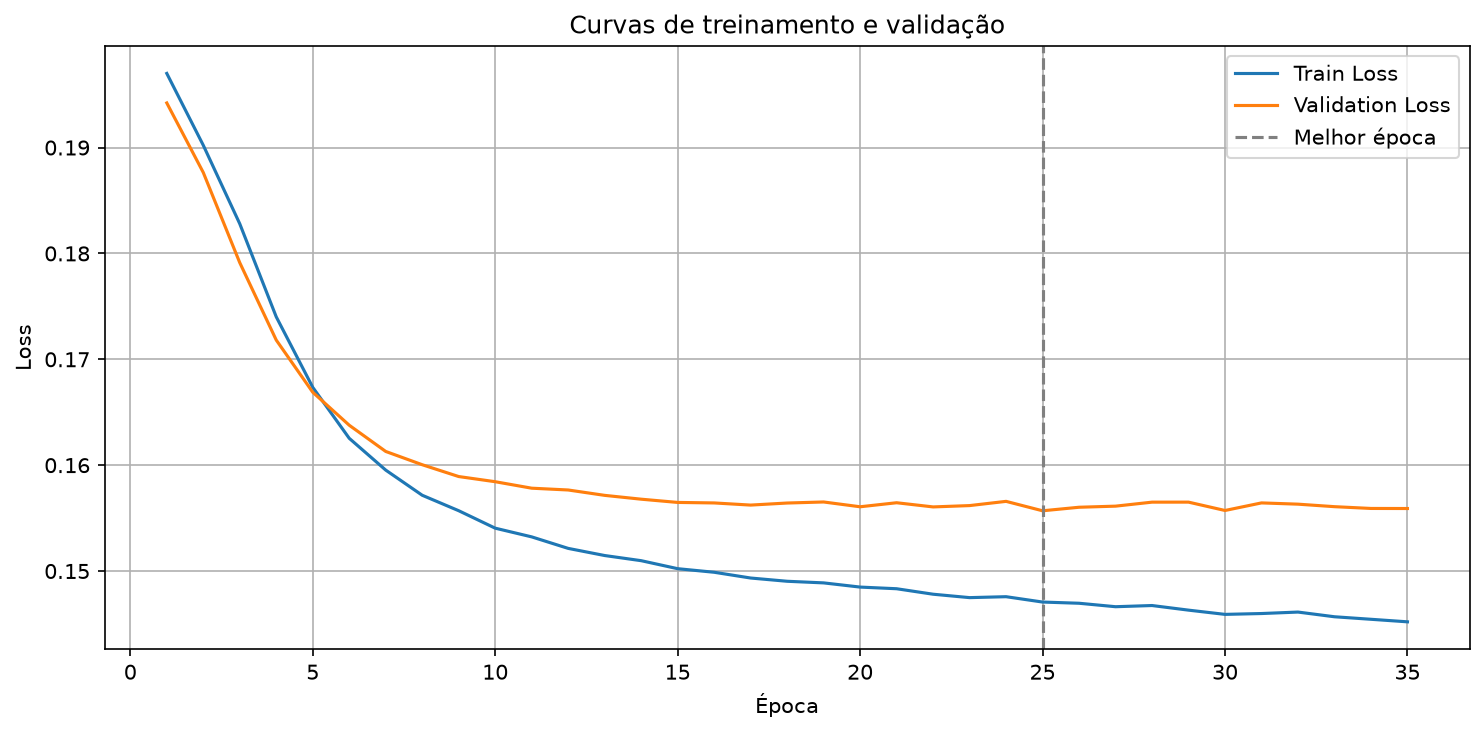

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss")
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Validation Loss")

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curvas de treinamento e validação")
plt.legend()
plt.grid()
plt.axvline(best_epoch, color="gray", linestyle="--", label="Melhor época")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig03-curvas-treino.png", dpi=150, bbox_inches="tight")
mostrar_e_fechar(plt.gcf())

In [22]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

modelo_mlp.eval()

with torch.no_grad():
    val_logits = modelo_mlp(X_val_tensor).squeeze(1)
    y_val_proba_mlp = torch.sigmoid(val_logits).numpy()

In [23]:
y_val_pred_mlp = (y_val_proba_mlp >= 0.5).astype(int)

print("PR-AUC:", average_precision_score(y_val, y_val_proba_mlp))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_mlp))
print("Precision:", precision_score(y_val, y_val_pred_mlp, zero_division=0))
print("Recall:", recall_score(y_val, y_val_pred_mlp, zero_division=0))
print("F1-score:", f1_score(y_val, y_val_pred_mlp, zero_division=0))

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_val_pred_mlp))

PR-AUC: 0.23363442377772606
ROC-AUC: 0.8422236503856042
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Matriz de confusão:
[[778   0]
 [ 40   0]]


In [24]:
print("Probabilidade mínima:", y_val_proba_mlp.min())
print("Probabilidade máxima:", y_val_proba_mlp.max())
print("Média:", y_val_proba_mlp.mean())

print(
    "Exemplos classificados como positivos:",
    (y_val_proba_mlp >= 0.5).sum()
)

Probabilidade mínima: 0.00015578288
Probabilidade máxima: 0.38232547
Média: 0.04904781
Exemplos classificados como positivos: 0


In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:
    y_pred = (y_val_proba_mlp >= threshold).astype(int)

    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.05 | Precision: 0.1328 | Recall: 0.8500 | F1: 0.2297
Threshold: 0.10 | Precision: 0.1544 | Recall: 0.5750 | F1: 0.2434
Threshold: 0.15 | Precision: 0.1628 | Recall: 0.3500 | F1: 0.2222
Threshold: 0.20 | Precision: 0.2500 | Recall: 0.2750 | F1: 0.2619
Threshold: 0.25 | Precision: 0.3846 | Recall: 0.1250 | F1: 0.1887
Threshold: 0.30 | Precision: 0.5000 | Recall: 0.0500 | F1: 0.0909
Threshold: 0.40 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Threshold: 0.50 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000


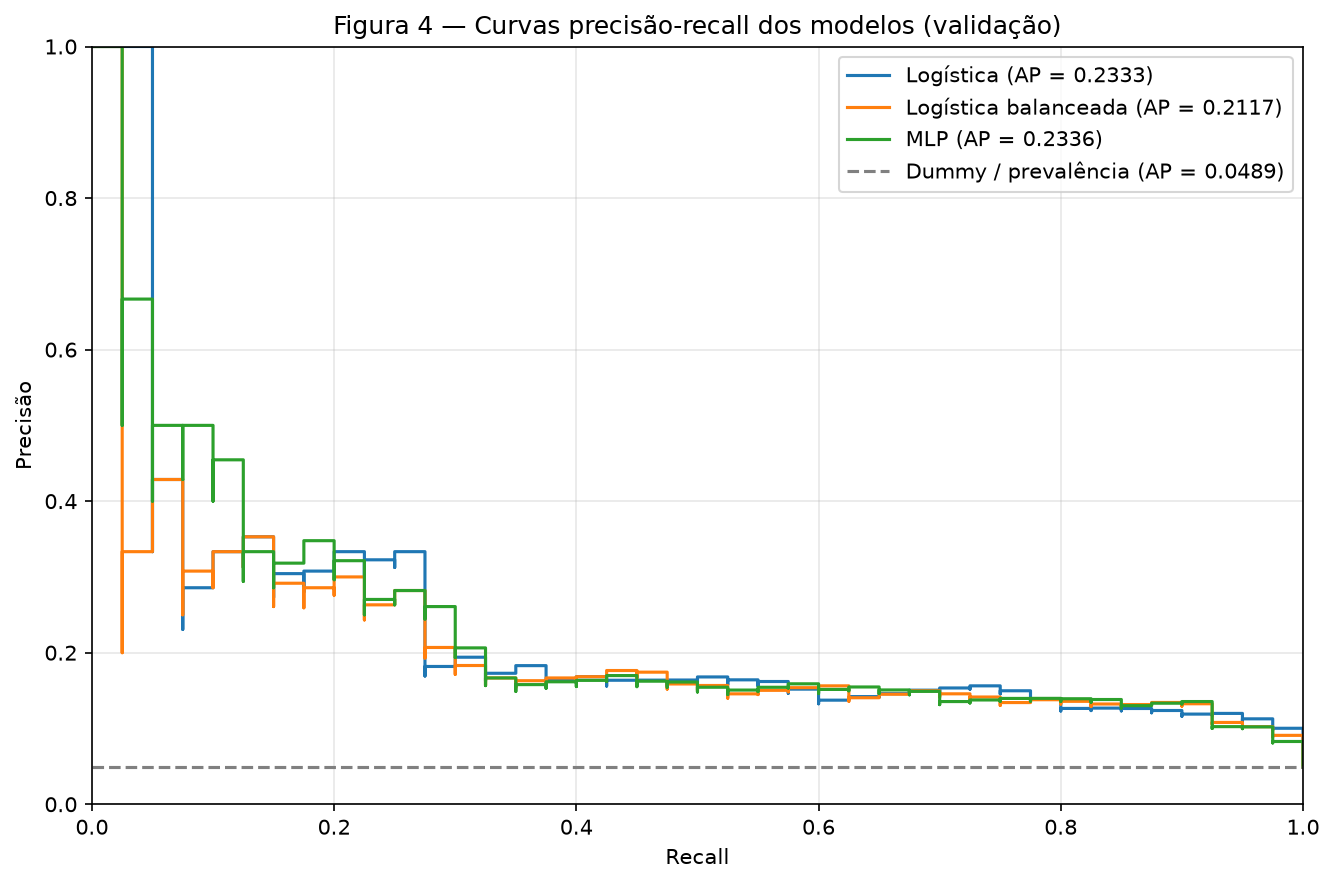

In [26]:
# Comparação somente na validação; o teste permanece reservado.
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(9, 6))
try:
    for nome, proba in [
        ("Logística", resultados["Logística"]["proba"]),
        ("Logística balanceada", resultados["Logística balanceada"]["proba"]),
        ("MLP", y_val_proba_mlp),
    ]:
        precisao, recall, _ = precision_recall_curve(y_val, proba)
        ap = average_precision_score(y_val, proba)
        ax.step(recall, precisao, where="post", label=f"{nome} (AP = {ap:.4f})")
    # Scores constantes: referência horizontal, sem ligar os extremos em diagonal.
    ap_dummy = average_precision_score(y_val, resultados["Dummy"]["proba"])
    ax.axhline(float(y_val.mean()), color="gray", linestyle="--",
               label=f"Dummy / prevalência (AP = {ap_dummy:.4f})")
    ax.set(xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1),
           title="Figura 4 — Curvas precisão-recall dos modelos (validação)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIGURES / "fig04-modelos-pr-validacao.png", dpi=150, bbox_inches="tight")
    mostrar_e_fechar(fig)
finally:
    plt.close(fig)


In [27]:
import imblearn
# Usa o pré-processador já ajustado somente em X_train_sub.
X_smote, y_smote, sampler = balance_training(
    preprocess, X_train_sub, y_train_sub
)

n_positivos = int(y_train_sub.sum())
n_negativos = len(y_train_sub) - n_positivos
peso_positivo = n_negativos / n_positivos

dados_desbalanceamento = {
    "Nenhum": (
        X_train_tensor,
        y_train_tensor,
        None,
    ),
    "pos_weight": (
        X_train_tensor,
        y_train_tensor,
        torch.tensor(peso_positivo, dtype=torch.float32),
    ),
    "SMOTENC": (
        torch.tensor(X_smote, dtype=torch.float32),
        torch.tensor(np.asarray(y_smote), dtype=torch.float32),
        None,
    ),
}

print(f"pos_weight = {peso_positivo:.2f}")
print(f"Treino original: {len(y_train_sub)} pacientes; {n_positivos} positivos")
print(f"Treino SMOTENC: {len(y_smote)} exemplos; {int(np.sum(y_smote))} positivos")

pos_weight = 19.57
Treino original: 3270 pacientes; 159 positivos
Treino SMOTENC: 6222 exemplos; 3111 positivos


In [28]:
def comparar_tratamento(nome, semente, max_epocas=100, paciencia=10):
    fixar_semente(semente)
    modelo = MLP()

    X_treino, y_treino, peso = dados_desbalanceamento[nome]
    perda_treino = nn.BCEWithLogitsLoss(pos_weight=peso)

    otimizador = torch.optim.AdamW(
        modelo.parameters(), lr=0.001, weight_decay=0.0
    )

    loader = DataLoader(
        TensorDataset(X_treino, y_treino),
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(semente),
        num_workers=0,
    )

    melhor_ap = -float("inf")
    melhores_pesos = None
    melhor_epoca = 0
    sem_melhora = 0

    for epoca in range(1, max_epocas + 1):
        modelo.train()
        for xb, yb in loader:
            otimizador.zero_grad()
            perda = perda_treino(modelo(xb).squeeze(1), yb)
            perda.backward()
            otimizador.step()

        modelo.eval()
        with torch.no_grad():
            probabilidades = torch.sigmoid(
                modelo(X_val_tensor).squeeze(1)
            ).cpu().numpy()

        ap_val = average_precision_score(y_val, probabilidades)

        if ap_val > melhor_ap:
            melhor_ap = ap_val
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            melhor_epoca = epoca
            sem_melhora = 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break

    modelo.load_state_dict(melhores_pesos)

    return {
        "tratamento": nome,
        "semente": semente,
        "PR-AUC": melhor_ap,
        "melhor época": melhor_epoca,
        "épocas executadas": epoca,
    }

In [29]:
resultados_desbalanceamento = []

for nome in dados_desbalanceamento:
    for semente in range(5):
        resultado = comparar_tratamento(nome, semente)
        resultados_desbalanceamento.append(resultado)
        print(
            f"{nome:12s} | semente {semente} | "
            f"PR-AUC {resultado['PR-AUC']:.4f} | "
            f"melhor época {resultado['melhor época']}"
        )

detalhes_desbalanceamento = pd.DataFrame(resultados_desbalanceamento)

tabela_desbalanceamento = (
    detalhes_desbalanceamento.groupby("tratamento")
    .agg(
        pr_auc_media=("PR-AUC", "mean"),
        pr_auc_desvio=("PR-AUC", "std"),
        melhor_epoca_media=("melhor época", "mean"),
        epocas_executadas_media=("épocas executadas", "mean"),
    )
    .sort_values("pr_auc_media", ascending=False)
)

display(tabela_desbalanceamento.round(4))

Nenhum       | semente 0 | PR-AUC 0.2102 | melhor época 16
Nenhum       | semente 1 | PR-AUC 0.2392 | melhor época 28
Nenhum       | semente 2 | PR-AUC 0.2413 | melhor época 42
Nenhum       | semente 3 | PR-AUC 0.2347 | melhor época 32
Nenhum       | semente 4 | PR-AUC 0.2348 | melhor época 32
pos_weight   | semente 0 | PR-AUC 0.2191 | melhor época 22
pos_weight   | semente 1 | PR-AUC 0.2210 | melhor época 31
pos_weight   | semente 2 | PR-AUC 0.2051 | melhor época 39
pos_weight   | semente 3 | PR-AUC 0.2576 | melhor época 60
pos_weight   | semente 4 | PR-AUC 0.2152 | melhor época 23
SMOTENC      | semente 0 | PR-AUC 0.1533 | melhor época 11
SMOTENC      | semente 1 | PR-AUC 0.1602 | melhor época 13
SMOTENC      | semente 2 | PR-AUC 0.1351 | melhor época 5
SMOTENC      | semente 3 | PR-AUC 0.1674 | melhor época 13
SMOTENC      | semente 4 | PR-AUC 0.1444 | melhor época 12


,pr_auc_media,pr_auc_desvio,melhor_epoca_media,epocas_executadas_media
tratamento,,,,
Nenhum,0.2320,0.0125,30.0,40.0
pos_weight,0.2236,0.0200,35.0,45.0
SMOTENC,0.1521,0.0127,10.8,20.8


## Etapa 4 — Regularização e hiperparâmetros

A rede e o loop de treino desta etapa estão em [`mlp.py`](mlp.py): `construir_mlp` monta a MLP com dropout e BatchNorm opcionais e `treinar_mlp` treina com AdamW, weight decay aplicado só às matrizes de pesos e parada antecipada pela perda de validação, restaurando os melhores pesos. Todas as comparações usam a mesma divisão, as mesmas 5 sementes e apenas a validação; o teste continua reservado para a etapa 5.

### Diagnóstico: overfitting ou underfitting?

Antes de regularizar, treino e validação são lidos juntos, como recomenda a aula de Regularização. A rede base (24-8-1, AdamW com lr = 0,001, batch 32) é treinada por 100 épocas sem parar, e a PR-AUC é medida na melhor época de validação e na última época.


In [30]:
import math
sys.path.insert(0, str(BASE / "docs" / "projects" / "classification" / "code"))
from mlp import treinar_mlp

SEMENTES = range(5)
vies_inicial = math.log(float(y_train_sub.mean()) / (1 - float(y_train_sub.mean())))
dados = (X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor)

diagnostico = pd.DataFrame(
    [treinar_mlp(*dados, s, vies_saida=vies_inicial, paciencia=None)[1] for s in SEMENTES]
)
tabela_diagnostico = pd.DataFrame({
    "PR-AUC treino": [diagnostico["PR-AUC treino"].mean(),
                      diagnostico["PR-AUC treino (última época)"].mean()],
    "PR-AUC validação": [diagnostico["PR-AUC validação"].mean(),
                         diagnostico["PR-AUC validação (última época)"].mean()],
}, index=[f"melhor época (média {diagnostico['melhor época'].mean():.0f})",
          "última época (100)"])
tabela_diagnostico["distância treino − validação"] = (
    tabela_diagnostico["PR-AUC treino"] - tabela_diagnostico["PR-AUC validação"])
print("Tabela 4.1 — Diagnóstico da rede base (média de 5 sementes)")
display(tabela_diagnostico.round(3))


Tabela 4.1 — Diagnóstico da rede base (média de 5 sementes)


,PR-AUC treino,PR-AUC validação,distância treino − validação
melhor época (média 22),0.259,0.220,0.039
última época (100),0.354,0.211,0.143


**Leitura.** Sem parada antecipada, o treino continua melhorando até a época 100 (PR-AUC 0,354) enquanto a validação piora (0,211): a distância entre os dois sobe de 0,039 para 0,143. É overfitting, e ele começa por volta da época 22, a melhor época média. Na melhor época, treino (0,259) e validação (0,220) ficam próximos, então a parada antecipada já contém a maior parte da memorização. Não é underfitting por falta de capacidade: a rede alcança 0,354 no treino, e redes mais largas pioraram a validação (etapa 2). A regularização deve, portanto, atacar o overfitting, sem aumentar a rede.

### Técnicas comparadas com a rede sem regularização

Três técnicas são comparadas com a rede sem regularização, todas com a parada antecipada mantida:

- **Weight decay** (0,01 e 0,1, a faixa que a aula indica para AdamW): encolhe os pesos a cada passo, atacando diretamente a memorização, que exige pesos grandes. Vieses e parâmetros da BatchNorm ficam fora da penalidade.
- **Dropout** (0,1 e 0,2): desliga neurônios ao acaso a cada passo, impedindo co-adaptações. Os valores são baixos porque a rede tem só 8 neurônios ocultos; a aula alerta que dropout alto destrói uma rede pequena.
- **BatchNorm**: padroniza a saída da camada oculta com as estatísticas de cada mini-batch, o que injeta ruído no treino. Ordem usada: Linear → BatchNorm → ReLU → Dropout.


In [31]:
tecnicas = {
    "sem regularização": {},
    "weight decay 0,01": {"weight_decay": 0.01},
    "weight decay 0,1": {"weight_decay": 0.1},
    "dropout 0,1": {"dropout": 0.1},
    "dropout 0,2": {"dropout": 0.2},
    "BatchNorm": {"batchnorm": True},
}

def resumir(config):
    res = pd.DataFrame([treinar_mlp(*dados, s, vies_saida=vies_inicial, **config)[1]
                        for s in SEMENTES])
    return {
        "PR-AUC treino": res["PR-AUC treino"].mean(),
        "desvio": res["PR-AUC validação"].std(),
        "PR-AUC validação": res["PR-AUC validação"].mean(),
        "distância treino − validação": (res["PR-AUC treino"] - res["PR-AUC validação"]).mean(),
        "melhor época": res["melhor época"].mean(),
    }

tabela_tecnicas = pd.DataFrame({nome: resumir(cfg) for nome, cfg in tecnicas.items()}).T
print("Tabela 4.2 — Técnicas de regularização (lr = 0,001; média de 5 sementes)")
display(tabela_tecnicas.round(3))


Tabela 4.2 — Técnicas de regularização (lr = 0,001; média de 5 sementes)


,PR-AUC treino,desvio,PR-AUC validação,distância treino − validação,melhor época
sem regularização,0.259,0.014,0.220,0.039,21.8
"weight decay 0,01",0.259,0.016,0.219,0.040,22.0
"weight decay 0,1",0.260,0.017,0.219,0.041,26.0
"dropout 0,1",0.261,0.011,0.218,0.043,25.2
"dropout 0,2",0.257,0.017,0.219,0.038,32.6
BatchNorm,0.305,0.016,0.233,0.072,18.4


**Leitura.** Weight decay e dropout não mudaram o resultado além do ruído: todas as versões ficam entre 0,218 e 0,219, contra 0,220 sem regularização, com desvio de 0,011 a 0,017 entre sementes e a mesma distância treino − validação (≈ 0,04). Isso é coerente com o diagnóstico: com a parada antecipada a rede quase não chega a decorar, e sobra pouco para regularizar; a aula também lembra que dropout é técnica para redes com capacidade de sobra, o que não é o caso de 8 neurônios ocultos. A BatchNorm foi a única com efeito visível, 0,233 ± 0,016 (+0,013, cerca de 1 desvio), mas ela aumentou a PR-AUC de treino (0,305) e a distância para a validação (0,072): não agiu como regularizadora, e sim ajudou a rede a se ajustar melhor, que é o papel principal que a aula atribui à normalização (facilitar a otimização).

### Busca de hiperparâmetros

A busca cruza a taxa de aprendizado, o único fator com efeito consistente nos testes anteriores, com as três técnicas: taxa {0,001; 0,003} × dropout {0; 0,2} × weight decay {0; 0,01} × BatchNorm {não; sim}, em 16 configurações com 5 sementes cada. A largura fica em 8, escolhida na etapa 2.

**Regra de escolha, definida antes de rodar a busca:** fica a configuração de maior PR-AUC média na validação; se outras ficarem a menos de 1 desvio dela, escolhe-se entre essas a que usa menos técnicas de regularização e, em empate, a de menor desvio. Com só 40 casos de AVC na validação, a regra evita escolher o vencedor pelo ruído.


In [32]:
import itertools

linhas = []
for lr, dropout, wd, bn in itertools.product([0.001, 0.003], [0.0, 0.2], [0.0, 0.01], [False, True]):
    linha = {"taxa": lr, "dropout": dropout, "weight decay": wd, "BatchNorm": bn}
    linha.update(resumir({"lr": lr, "dropout": dropout, "weight_decay": wd, "batchnorm": bn}))
    linha["técnicas"] = int(dropout > 0) + int(wd > 0) + int(bn)
    linhas.append(linha)

tabela_busca = (pd.DataFrame(linhas)
                .sort_values("PR-AUC validação", ascending=False)
                .reset_index(drop=True))
tabela_busca.index += 1
print("Tabela 4.3 — Busca de hiperparâmetros, ordenada pela PR-AUC na validação (5 sementes)")
display(tabela_busca.round(4))

# Regra de escolha
melhor = tabela_busca.iloc[0]
limite = melhor["PR-AUC validação"] - melhor["desvio"]
candidatas = tabela_busca[tabela_busca["PR-AUC validação"] >= limite]
escolhida = candidatas.sort_values(["técnicas", "desvio"]).iloc[0]
config_escolhida = {"lr": float(escolhida["taxa"]), "dropout": float(escolhida["dropout"]),
                    "weight_decay": float(escolhida["weight decay"]),
                    "batchnorm": bool(escolhida["BatchNorm"])}
print(f"Melhor média: {melhor['PR-AUC validação']:.4f} ± {melhor['desvio']:.4f} -> limite {limite:.4f}")
print(f"{len(candidatas)} configurações dentro de 1 desvio da melhor")
print("Configuração escolhida:", config_escolhida,
      f"| PR-AUC {escolhida['PR-AUC validação']:.4f} ± {escolhida['desvio']:.4f}",
      f"| melhor época {escolhida['melhor época']:.1f}")


Tabela 4.3 — Busca de hiperparâmetros, ordenada pela PR-AUC na validação (5 sementes)


,taxa,dropout,weight decay,BatchNorm,PR-AUC treino,desvio,PR-AUC validação,distância treino − validação,melhor época,técnicas
1,0.001,0.0,0.01,True,0.3092,0.0212,0.2373,0.0719,19.8,2
2,0.003,0.2,0.01,True,0.2899,0.0103,0.2363,0.0536,11.4,3
3,0.001,0.2,0.01,True,0.2898,0.0141,0.2359,0.0539,20.6,3
4,0.003,0.2,0.00,True,0.2881,0.0140,0.2350,0.0531,10.4,2
5,0.003,0.0,0.00,True,0.2980,0.0159,0.2342,0.0638,8.6,1
6,0.001,0.0,0.00,True,0.3049,0.0163,0.2327,0.0722,18.4,1
7,0.003,0.0,0.01,True,0.3039,0.0170,0.2314,0.0725,9.4,2
8,0.001,0.2,0.00,True,0.2895,0.0141,0.2299,0.0596,20.8,2
9,0.003,0.2,0.01,False,0.2588,0.0082,0.2290,0.0298,12.4,2
10,0.003,0.2,0.00,False,0.2632,0.0063,0.2288,0.0344,12.2,1


Melhor média: 0.2373 ± 0.0212 -> limite 0.2161
16 configurações dentro de 1 desvio da melhor
Configuração escolhida: {'lr': 0.003, 'dropout': 0.0, 'weight_decay': 0.0, 'batchnorm': False} | PR-AUC 0.2282 ± 0.0096 | melhor época 9.2


**Leitura e escolha.** As 8 primeiras configurações usam BatchNorm (PR-AUC entre 0,230 e 0,237) e, dentro de cada taxa, toda configuração com BatchNorm supera todas as sem ela: um padrão consistente, mas pequeno. A taxa de 0,003 convergiu mais rápido (melhor época entre ≈ 8 e 12, contra ≈ 16 a 33 com 0,001) sem perder desempenho. Dropout e weight decay seguem sem efeito sistemático.

A melhor configuração (taxa 0,001, weight decay 0,01 e BatchNorm) obteve 0,237 ± 0,021. Pela regra definida antes da busca, todas as 16 configurações ficam a menos de 1 desvio dela, e a mais simples entre elas é a **rede sem regularização com taxa 0,003** (0,228 ± 0,010, melhor época ≈ 9), que segue para a etapa 5. A diferença para a melhor (0,009) é menor que o desvio entre sementes, então não há evidência suficiente para justificar técnicas a mais. Os resultados com BatchNorm também variam ligeiramente de um computador para outro (as configurações sem ela se reproduzem exatamente), outro motivo para não depender dela. Conclusão da etapa: com uma rede pequena e parada antecipada, a regularização explícita não trouxe ganho distinguível do ruído; a parada antecipada já cumpre esse papel.

## Etapa 5 — Avaliação no teste

A configuração escolhida na etapa 4 (`config_escolhida`: 24-8-1, AdamW com taxa 0,003, sem regularização) é retreinada com 3 sementes, no mesmo treino (3.270 pacientes) e com a mesma parada antecipada pela validação. Os baselines são os mesmos da etapa 1, já ajustados nesse treino.

O limiar de decisão de cada modelo é escolhido **na validação**, pela regra da etapa 0: o maior limiar que mantém o recall de AVC em pelo menos 0,80. Esse limiar é então aplicado ao teste.

**O teste é usado uma única vez, nesta seção, e nada (arquitetura, regularização, limiar ou referência) foi escolhido a partir dele.**


In [33]:
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                             precision_recall_fscore_support)

RECALL_MINIMO = 0.80
SEMENTES_TESTE = [0, 1, 2]

X_test_tensor = torch.tensor(preprocess.transform(X_test), dtype=torch.float32)
y_teste = y_test.to_numpy()
y_valid = y_val.to_numpy()


def limiar_por_recall(y, proba, recall_min=RECALL_MINIMO):
    """Maior limiar cujo recall de AVC é >= recall_min."""
    for t in np.sort(np.unique(proba))[::-1]:
        if ((proba >= t) & (y == 1)).sum() / (y == 1).sum() >= recall_min:
            return float(t)


def metricas_teste(nome, proba_val, proba_teste):
    """Limiar escolhido na validação; métricas calculadas no teste."""
    limiar = limiar_por_recall(y_valid, proba_val)
    pred = (proba_teste >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, pred, labels=[0, 1]).ravel()
    p, r, f, _ = precision_recall_fscore_support(y_teste, pred, labels=[0, 1], zero_division=0)
    return {"modelo": nome, "limiar (validação)": limiar,
            "PR-AUC": average_precision_score(y_teste, proba_teste),
            "ROC-AUC": roc_auc_score(y_teste, proba_teste),
            "marcados": int(pred.sum()), "VP": int(vp), "FN": int(fn), "FP": int(fp), "VN": int(vn),
            "precisão AVC": p[1], "recall AVC": r[1], "F1 AVC": f[1],
            "precisão sem AVC": p[0], "recall sem AVC": r[0], "F1 sem AVC": f[0],
            "F1 macro": f.mean()}


# Rede: retreinada com 3 sementes
linhas_rede, probas_rede_teste = [], {}
for s in SEMENTES_TESTE:
    modelo_final, info = treinar_mlp(*dados, s, vies_saida=vies_inicial, **config_escolhida)
    modelo_final.eval()
    with torch.no_grad():
        p_val = torch.sigmoid(modelo_final(X_val_tensor).squeeze(1)).numpy()
        p_teste = torch.sigmoid(modelo_final(X_test_tensor).squeeze(1)).numpy()
    linha = metricas_teste(f"MLP semente {s}", p_val, p_teste)
    linha["melhor época"] = info["melhor época"]
    linhas_rede.append(linha)
    probas_rede_teste[s] = p_teste
rede_teste = pd.DataFrame(linhas_rede).set_index("modelo")

# Baselines da etapa 1 (ajustados no mesmo treino)
baselines_teste = pd.DataFrame([
    metricas_teste(nome, r["proba"], r["modelo"].predict_proba(X_test)[:, 1])
    for nome, r in resultados.items()
]).set_index("modelo")

colunas = ["PR-AUC", "ROC-AUC", "recall AVC", "precisão AVC", "F1 AVC",
           "recall sem AVC", "precisão sem AVC", "F1 sem AVC", "F1 macro"]
tabela_teste = baselines_teste[colunas].copy()
tabela_teste.loc["MLP — média de 3 sementes"] = rede_teste[colunas].mean()
tabela_teste.loc["MLP — desvio entre sementes"] = rede_teste[colunas].std()
print(f"Teste: {len(y_teste)} pacientes, {int(y_teste.sum())} com AVC")
print("Tabela 5.1 — Rede × baselines no teste (limiar escolhido na validação, recall ≥ 0,80)")
display(tabela_teste.round(3))
print("Resultados da rede por semente")
display(rede_teste[["limiar (validação)", "melhor época", "PR-AUC", "ROC-AUC",
                    "recall AVC", "precisão AVC", "F1 macro"]].round(3))


Teste: 1022 pacientes, 50 com AVC
Tabela 5.1 — Rede × baselines no teste (limiar escolhido na validação, recall ≥ 0,80)


,PR-AUC,ROC-AUC,recall AVC,precisão AVC,F1 AVC,recall sem AVC,precisão sem AVC,F1 sem AVC,F1 macro
modelo,,,,,,,,,
Dummy,0.049,0.500,1.000,0.049,0.093,0.000,0.000,0.000,0.047
Logística,0.250,0.843,0.800,0.144,0.244,0.755,0.987,0.855,0.550
Logística balanceada,0.235,0.842,0.800,0.141,0.240,0.750,0.986,0.852,0.546
MLP — média de 3 sementes,0.225,0.839,0.813,0.156,0.262,0.773,0.988,0.867,0.565
MLP — desvio entre sementes,0.012,0.004,0.012,0.005,0.008,0.006,0.001,0.004,0.006


Resultados da rede por semente


,limiar (validação),melhor época,PR-AUC,ROC-AUC,recall AVC,precisão AVC,F1 macro
modelo,,,,,,,
MLP semente 0,0.065,8,0.227,0.841,0.82,0.159,0.568
MLP semente 1,0.060,15,0.212,0.834,0.80,0.150,0.558
MLP semente 2,0.070,7,0.236,0.841,0.82,0.159,0.568


**Leitura.** No resumo de todos os limiares, a rede ficou abaixo dos dois modelos lineares: PR-AUC de 0,225 ± 0,012 contra 0,250 da Regressão Logística e 0,235 da Logística balanceada; na ROC-AUC os três praticamente empatam (0,839 a 0,843). O Dummy marca o piso (PR-AUC 0,049).

No ponto de operação, porém, a ordem se inverte levemente. Com o limiar escolhido na validação, a rede atinge recall de AVC de 0,813 com precisão de 0,156 e F1 macro de 0,565, contra 0,800, 0,144 e 0,550 da Logística. A PR-AUC resume a curva inteira, e a vantagem da Logística está em outras regiões dela; perto de recall 0,80, onde o modelo vai operar, as duas curvas estão muito próximas (Figura 5). O limiar escolhido na validação também se manteve no teste: todos os modelos ficaram com recall entre 0,80 e 0,82, a meta da etapa 0.

In [34]:
# Critério de sucesso da etapa 0 e incerteza da diferença
logisticas = baselines_teste.loc[["Logística", "Logística balanceada"]]
nome_ref = logisticas["PR-AUC"].idxmax()
pr_ref = logisticas.loc[nome_ref, "PR-AUC"]
meta = 1.10 * pr_ref
pr_rede, dp_rede = rede_teste["PR-AUC"].mean(), rede_teste["PR-AUC"].std()

print(f"Melhor Logística no teste: {nome_ref} (PR-AUC {pr_ref:.3f})")
print(f"Meta (+10%): {meta:.3f}")
print(f"MLP: {pr_rede:.3f} ± {dp_rede:.3f} -> critério atingido? {'sim' if pr_rede >= meta else 'não'}")
print(f"Diferença MLP − {nome_ref}: {pr_rede - pr_ref:+.3f} (desvio entre sementes: {dp_rede:.3f})")

# Bootstrap pareado nos pacientes do teste: quanto a diferença varia
# conforme quais pacientes caíram no teste
rng = np.random.default_rng(0)
p_ref = resultados[nome_ref]["modelo"].predict_proba(X_test)[:, 1]
diferencas = []
for _ in range(2000):
    idx = rng.integers(0, len(y_teste), len(y_teste))
    if y_teste[idx].sum() == 0:
        continue
    ap_rede = np.mean([average_precision_score(y_teste[idx], probas_rede_teste[s][idx])
                       for s in SEMENTES_TESTE])
    diferencas.append(ap_rede - average_precision_score(y_teste[idx], p_ref[idx]))
ic = np.percentile(diferencas, [2.5, 97.5])
print(f"Bootstrap (2.000 reamostragens): IC 95% da diferença = [{ic[0]:+.3f}, {ic[1]:+.3f}]; "
      f"MLP melhor em {np.mean(np.array(diferencas) > 0):.0%} das reamostragens")


Melhor Logística no teste: Logística (PR-AUC 0.250)
Meta (+10%): 0.275
MLP: 0.225 ± 0.012 -> critério atingido? não
Diferença MLP − Logística: -0.025 (desvio entre sementes: 0.012)


Bootstrap (2.000 reamostragens): IC 95% da diferença = [-0.068, +0.005]; MLP melhor em 6% das reamostragens


**Critério de sucesso: não atingido.** A meta era uma PR-AUC pelo menos 10% acima da melhor Logística no teste, ou seja, 0,275 (1,10 × 0,250). A rede obteve 0,225 ± 0,012, 0,025 abaixo da Logística, uma diferença de cerca de 2 desvios entre sementes.

A variação entre sementes, porém, não é a única incerteza: o teste tem só 50 casos de AVC. O bootstrap pareado dos pacientes do teste dá um intervalo de 95% de [−0,068; +0,005] para a diferença, e a rede foi melhor em só 6% das reamostragens. A conclusão honesta é que a rede **não superou** a Regressão Logística, com tendência a ficar abaixo dela, mas o teste não tem tamanho para afirmar que ela é pior. Isso é coerente com o que a validação já indicava: com estas 10 variáveis, o sinal disponível é capturado quase todo por um modelo linear.

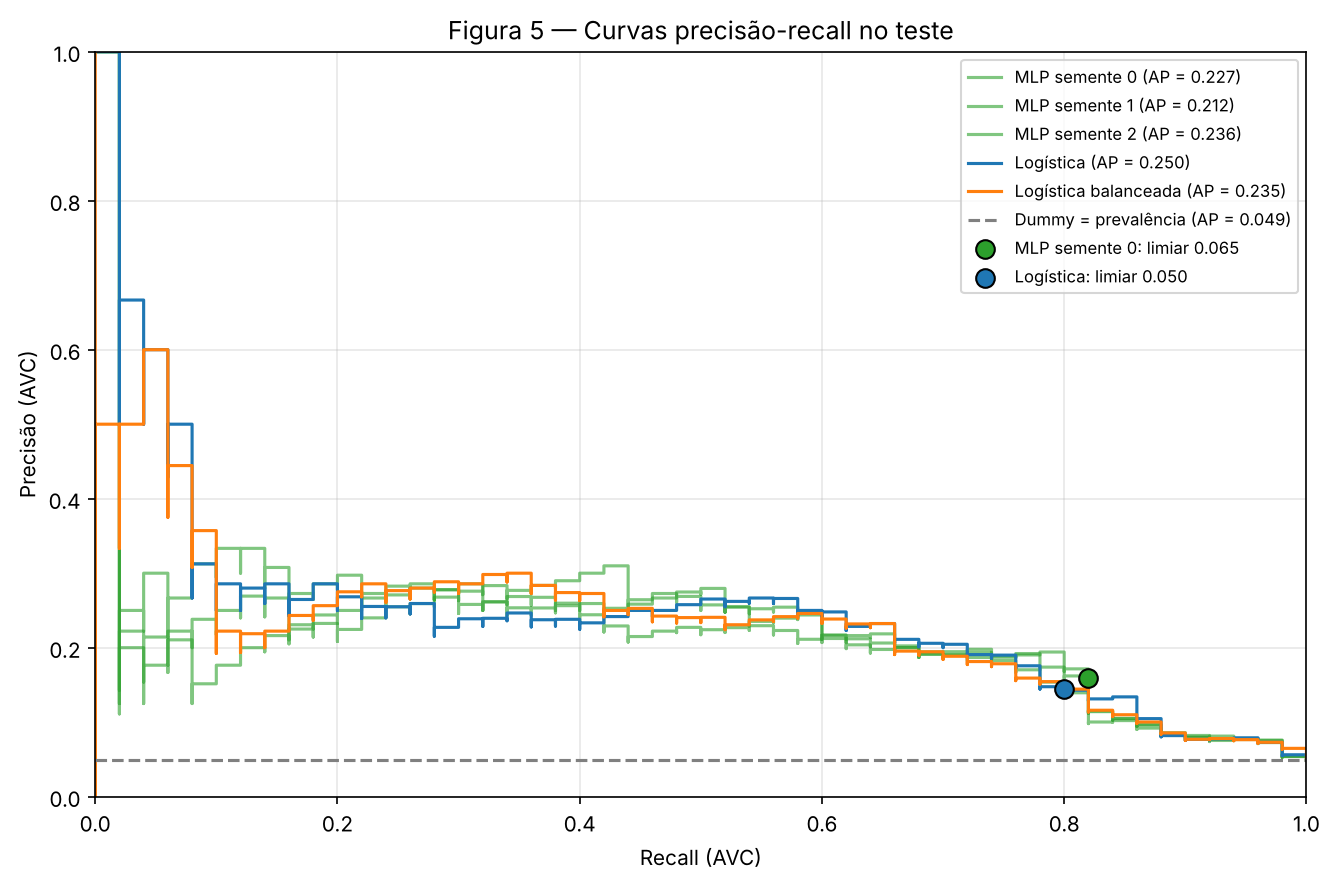

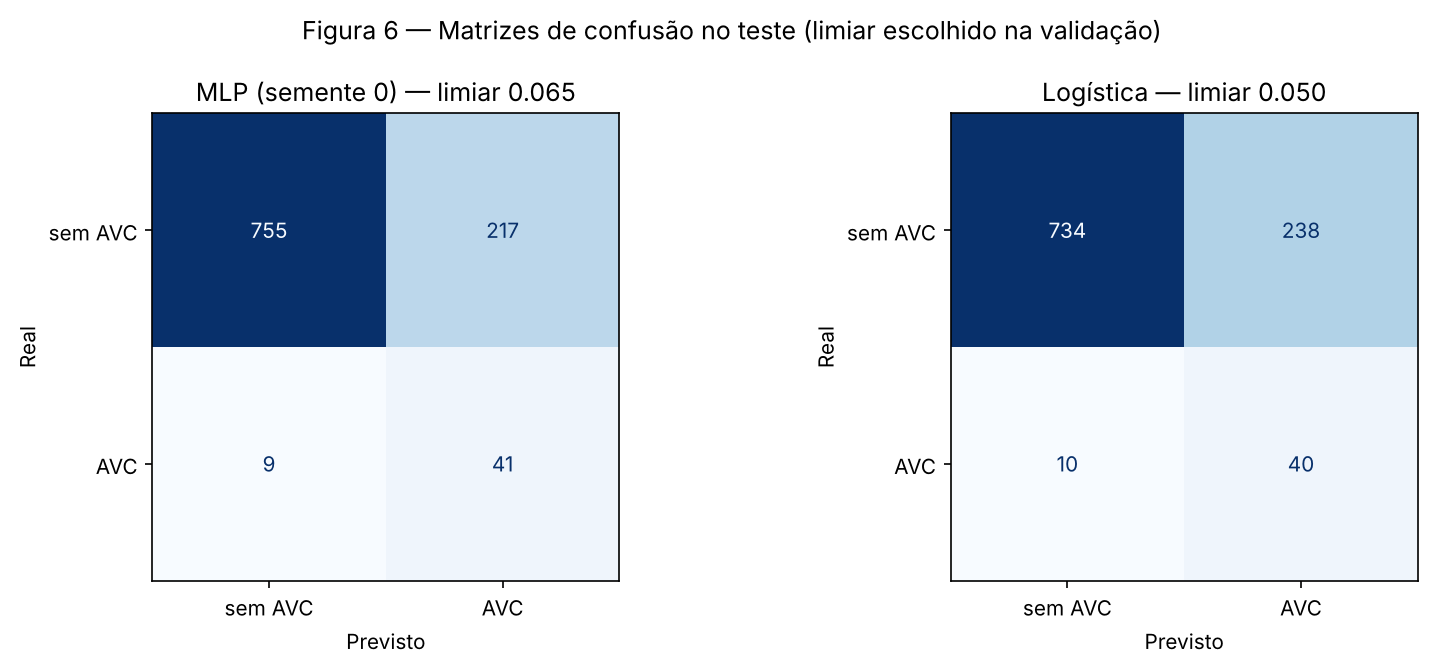

In [35]:
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

# Figura 5 — curvas precisão-recall no teste
fig, ax = plt.subplots(figsize=(9, 6))
try:
    for s in SEMENTES_TESTE:
        prec, rec, _ = precision_recall_curve(y_teste, probas_rede_teste[s])
        ax.step(rec, prec, where="post", color="tab:green", alpha=0.6,
                label=f"MLP semente {s} (AP = {rede_teste.loc[f'MLP semente {s}', 'PR-AUC']:.3f})")
    for nome, cor in [("Logística", "tab:blue"), ("Logística balanceada", "tab:orange")]:
        prec, rec, _ = precision_recall_curve(y_teste, resultados[nome]["modelo"].predict_proba(X_test)[:, 1])
        ax.step(rec, prec, where="post", color=cor,
                label=f"{nome} (AP = {baselines_teste.loc[nome, 'PR-AUC']:.3f})")
    ax.axhline(y_teste.mean(), color="gray", linestyle="--",
               label=f"Dummy = prevalência (AP = {baselines_teste.loc['Dummy', 'PR-AUC']:.3f})")
    # pontos de operação no limiar escolhido na validação
    for nome, linha, cor in [("MLP semente 0", rede_teste.loc["MLP semente 0"], "tab:green"),
                             ("Logística", baselines_teste.loc["Logística"], "tab:blue")]:
        ax.scatter(linha["recall AVC"], linha["precisão AVC"], color=cor, edgecolor="black",
                   s=80, zorder=5, label=f"{nome}: limiar {linha['limiar (validação)']:.3f}")
    ax.set(xlabel="Recall (AVC)", ylabel="Precisão (AVC)", xlim=(0, 1), ylim=(0, 1),
           title="Figura 5 — Curvas precisão-recall no teste")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIGURES / "fig05-pr-teste.png", dpi=150, bbox_inches="tight")
    mostrar_e_fechar(fig)
finally:
    plt.close(fig)

# Figura 6 — matrizes de confusão no teste, no limiar escolhido na validação
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
try:
    for ax, (titulo, proba, limiar) in zip(axes, [
        ("MLP (semente 0)", probas_rede_teste[0], rede_teste.loc["MLP semente 0", "limiar (validação)"]),
        ("Logística", resultados["Logística"]["modelo"].predict_proba(X_test)[:, 1],
         baselines_teste.loc["Logística", "limiar (validação)"]),
    ]):
        ConfusionMatrixDisplay.from_predictions(
            y_teste, (proba >= limiar).astype(int), display_labels=["sem AVC", "AVC"],
            cmap="Blues", colorbar=False, ax=ax)
        ax.set(xlabel="Previsto", ylabel="Real")
        ax.set_title(f"{titulo} — limiar {limiar:.3f}")
    fig.suptitle("Figura 6 — Matrizes de confusão no teste (limiar escolhido na validação)")
    fig.tight_layout()
    fig.savefig(FIGURES / "fig06-confusao-teste.png", dpi=150, bbox_inches="tight")
    mostrar_e_fechar(fig)
finally:
    plt.close(fig)


### Análise individual do recall

Como definido na etapa 0, deixar passar um AVC custa mais do que um alarme falso. A tabela abaixo mostra, no limiar escolhido na validação, quantos dos 50 casos de AVC do teste cada modelo identifica e quantos alarmes falsos isso custa.


In [36]:
cols_recall = ["limiar (validação)", "marcados", "VP", "FN", "FP", "recall AVC", "precisão AVC"]
tabela_recall = pd.concat([baselines_teste[cols_recall], rede_teste[cols_recall]])
tabela_recall.loc["MLP — média de 3 sementes"] = rede_teste[cols_recall].mean()
tabela_recall["alarmes falsos por AVC identificado"] = tabela_recall["FP"] / tabela_recall["VP"]
print("Tabela 5.2 — Recall de AVC no teste (VP = casos de AVC identificados, FN = deixados passar, FP = alarmes falsos)")
display(tabela_recall.round(3))


Tabela 5.2 — Recall de AVC no teste (VP = casos de AVC identificados, FN = deixados passar, FP = alarmes falsos)


,limiar (validação),marcados,VP,FN,FP,recall AVC,precisão AVC,alarmes falsos por AVC identificado
modelo,,,,,,,,
Dummy,0.000,1022.0,50.000,0.000,972.000,1.000,0.049,19.440
Logística,0.050,278.0,40.000,10.000,238.000,0.800,0.144,5.950
Logística balanceada,0.485,283.0,40.000,10.000,243.000,0.800,0.141,6.075
MLP semente 0,0.065,258.0,41.000,9.000,217.000,0.820,0.159,5.293
MLP semente 1,0.060,267.0,40.000,10.000,227.000,0.800,0.150,5.675
MLP semente 2,0.070,258.0,41.000,9.000,217.000,0.820,0.159,5.293
MLP — média de 3 sementes,0.065,261.0,40.667,9.333,220.333,0.813,0.156,5.418


**Leitura.** No limiar escolhido na validação, a rede e as duas Logísticas identificam 40 a 41 dos 50 casos de AVC do teste e deixam passar 9 a 10. O custo é de cerca de 220 alarmes falsos para a rede (≈ 5,4 por AVC identificado) e 238 para a Logística (≈ 6,0). Na prática, cerca de 1 em cada 6 ou 7 pacientes marcados tem AVC, e 1 em cada 5 AVCs passa despercebido. O Dummy pega todos os casos apenas porque marca todos os pacientes (972 alarmes falsos, 19,4 por AVC). A vantagem da rede no ponto de operação (cerca de 18 alarmes falsos a menos e 1 caso a mais) é pequena e da ordem da variação entre as sementes (217 a 227 alarmes falsos).

## Etapa 6 — Análise de erros

A análise usa as previsões da rede no teste, já calculadas na etapa 5 (3 sementes, cada uma no limiar escolhido na validação). Nada aqui altera o modelo ou o limiar.

### Erro por subgrupo

Os subgrupos vêm das variáveis que o EDA destacou: faixa etária, hipertensão, doença cardíaca, IMC ausente, glicose acima do limite de 1,5 × IQR (calculado no treino, como no EDA) e tabagismo. Para cada subgrupo: o recall de AVC, quantos AVCs passam sem ser detectados, a taxa de alarme falso entre os pacientes sem AVC e o erro total (fração de pacientes classificados errado). Os valores são médias das 3 sementes.


In [37]:
preds_rede = {
    s: (probas_rede_teste[s] >= rede_teste.loc[f"MLP semente {s}", "limiar (validação)"]).astype(int)
    for s in SEMENTES_TESTE
}

teste = X_test.reset_index(drop=True).copy()
teste["AVC"] = y_teste
q1, q3 = X_train["avg_glucose_level"].quantile([0.25, 0.75])
limite_glicose = q3 + 1.5 * (q3 - q1)
teste["faixa etária"] = pd.cut(teste["age"], [0, 45, 65, 200], right=False,
                               labels=["< 45 anos", "45 a 64 anos", "≥ 65 anos"])
teste["hipertensão"] = teste["hypertension"].map({0: "não", 1: "sim"})
teste["doença cardíaca"] = teste["heart_disease"].map({0: "não", 1: "sim"})
teste["IMC"] = np.where(teste["bmi"].isna(), "ausente", "informado")
teste["glicose"] = np.where(teste["avg_glucose_level"] > limite_glicose,
                            f"> {limite_glicose:.1f} (extremo)", "dentro do limite")
teste["tabagismo"] = teste["smoking_status"]

linhas = []
for var in ["faixa etária", "hipertensão", "doença cardíaca", "IMC", "glicose", "tabagismo"]:
    for grupo, idx in teste.groupby(var, observed=True).groups.items():
        idx = np.asarray(idx)
        y = y_teste[idx]
        n, pos = len(idx), int(y.sum())
        fn = np.mean([((preds_rede[s][idx] == 0) & (y == 1)).sum() for s in SEMENTES_TESTE])
        fp = np.mean([((preds_rede[s][idx] == 1) & (y == 0)).sum() for s in SEMENTES_TESTE])
        linhas.append({"variável": var, "subgrupo": str(grupo), "pacientes": n, "AVC": pos,
                       "AVC (%)": 100 * pos / n,
                       "recall AVC": (pos - fn) / pos if pos else np.nan,
                       "AVCs não detectados": fn,
                       "taxa de alarme falso": fp / (n - pos),
                       "erro total": (fn + fp) / n})

tabela_subgrupos = pd.DataFrame(linhas).set_index(["variável", "subgrupo"])
print(f"Limite de glicose (1,5 × IQR no treino): {limite_glicose:.2f}")
print("Tabela 6.1 — Erro da rede por subgrupo no teste (média de 3 sementes)")
display(tabela_subgrupos.round(3))
maior = tabela_subgrupos["erro total"].idxmax()
print(f"Subgrupo com o maior erro total: {maior[0]} = {maior[1]} "
      f"({tabela_subgrupos.loc[maior, 'erro total']:.3f})")


Limite de glicose (1,5 × IQR no treino): 169.53
Tabela 6.1 — Erro da rede por subgrupo no teste (média de 3 sementes)


pacientes  AVC  AVC (%)  recall AVC  \
variável        subgrupo                                                 
faixa etária    < 45 anos                527    6    1.139       0.167   
                45 a 64 anos             295    9    3.051       0.519   
                ≥ 65 anos                200   35   17.500       1.000   
hipertensão     não                      921   38    4.126       0.763   
                sim                      101   12   11.881       0.972   
doença cardíaca não                      967   39    4.033       0.761   
                sim                       55   11   20.000       1.000   
IMC             ausente                   31    3    9.677       1.000   
                informado                991   47    4.743       0.801   
glicose         > 169.5 (extremo)        122   18   14.754       1.000   
                dentro do limite         900   32    3.556       0.708   
tabagismo       Unknown                  297    9    3.030       0.556   
                formerly smoked          171   14    8.187       0.905   
                never smoked             391   19    4.859       0.895   
                smokes                   163    8    4.908       0.750   

                                   AVCs não detectados  taxa de alarme falso  \
variável        subgrupo                                                       
faixa etária    < 45 anos                        5.000                 0.006   
                45 a 64 anos                     4.333                 0.219   
                ≥ 65 anos                        0.000                 0.937   
hipertensão     não                              9.000                 0.171   
                sim                              0.333                 0.779   
doença cardíaca não                              9.333                 0.204   
                sim                              0.000                 0.712   
IMC             ausente                          0.000                 0.631   
                informado                        9.333                 0.215   
glicose         > 169.5 (extremo)                0.000                 0.673   
                dentro do limite                 9.333                 0.173   
tabagismo       Unknown                          4.000                 0.074   
                formerly smoked                  1.333                 0.476   
                never smoked                     2.000                 0.229   
                smokes                           2.000                 0.252   

                                   erro total  
variável        subgrupo                       
faixa etária    < 45 anos               0.015  
                45 a 64 anos            0.227  
                ≥ 65 anos               0.773  
hipertensão     não                     0.174  
                sim                     0.690  
doença cardíaca não                     0.205  
                sim                     0.570  
IMC             ausente                 0.570  
                informado               0.214  
glicose         > 169.5 (extremo)       0.574  
                dentro do limite        0.177  
tabagismo       Unknown                 0.085  
                formerly smoked         0.444  
                never smoked            0.223  
                smokes                  0.252

Subgrupo com o maior erro total: faixa etária = ≥ 65 anos (0.773)


**Leitura.** O erro se organiza quase todo pela idade. Entre os pacientes com menos de 45 anos, a rede quase não dá alarme falso (0,6%), mas deixa passar 5 dos 6 AVCs (recall 0,17). Entre os de 65 anos ou mais, ela identifica todos os 35 AVCs, mas marca quase todo mundo: 94% dos pacientes sem AVC dessa faixa viram alarme falso, e esse é o **subgrupo com o maior erro total (0,773)**. O mesmo padrão aparece nos fatores de risco: com hipertensão, doença cardíaca, glicose acima de 169,5 ou IMC ausente, o recall fica entre 0,97 e 1,0 e a taxa de alarme falso entre 0,63 e 0,78. Os cerca de 9 AVCs que passam sem ser detectados estão todos entre pacientes com menos de 65 anos, sem hipertensão, sem doença cardíaca e com glicose dentro do limite.

**Hipóteses.** (1) No limiar escolhido para recall de 0,80, a rede funciona na prática como uma regra de risco por idade e comorbidades: ela não consegue distinguir, entre os pacientes de alto risco, quem teve AVC, porque a prevalência ali (17,5% entre os idosos) é alta e as 10 variáveis não trazem informação suficiente para separá-los. (2) Os AVCs em pacientes jovens e sem fatores de risco provavelmente têm causas que não estão registradas no dataset, e por isso nenhum modelo treinado nestas variáveis os encontraria. (3) O recall mais baixo no tabagismo `Unknown` (0,56) é reflexo da idade: o EDA (Tabela 6A) mostrou que essa categoria concentra pacientes mais jovens.

### Piores exemplos

Os piores erros são os de maior confiança: os pacientes com AVC que receberam as notas mais baixas (a rede os considerou de baixo risco) e os pacientes sem AVC com as notas mais altas. A nota é a média das 3 sementes.


In [38]:
teste["nota média"] = np.mean([probas_rede_teste[s] for s in SEMENTES_TESTE], axis=0)
colunas_ex = ["age", "gender", "hypertension", "heart_disease", "avg_glucose_level", "bmi",
              "smoking_status", "work_type", "ever_married", "nota média"]
limiar_medio = rede_teste["limiar (validação)"].mean()

piores_fn = teste[teste["AVC"] == 1].nsmallest(8, "nota média")[colunas_ex]
piores_fp = teste[teste["AVC"] == 0].nlargest(8, "nota média")[colunas_ex]
print(f"Limiar médio das 3 sementes: {limiar_medio:.3f}")
print("Tabela 6.2a — AVCs com as menores notas (falsos negativos de maior confiança)")
display(piores_fn.round(3))
print("Tabela 6.2b — Pacientes sem AVC com as maiores notas (alarmes falsos de maior confiança)")
display(piores_fp.round(3))


Limiar médio das 3 sementes: 0.065
Tabela 6.2a — AVCs com as menores notas (falsos negativos de maior confiança)


,age,gender,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,work_type,ever_married,nota média
553,14.0,Female,0,0,57.93,30.9,Unknown,children,No,0.001
240,32.0,Female,0,0,76.13,29.9,smokes,Private,Yes,0.008
686,42.0,Male,0,0,83.41,25.4,Unknown,Private,Yes,0.008
165,45.0,Male,0,0,64.14,29.4,never smoked,Private,Yes,0.010
521,39.0,Female,0,0,83.24,26.3,never smoked,Private,Yes,0.011
978,39.0,Female,0,0,97.76,29.6,smokes,Self-employed,Yes,0.013
253,47.0,Male,0,0,86.94,41.1,formerly smoked,Private,Yes,0.021
949,58.0,Male,0,0,92.62,32.0,Unknown,Private,No,0.028


Tabela 6.2b — Pacientes sem AVC com as maiores notas (alarmes falsos de maior confiança)


,age,gender,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,work_type,ever_married,nota média
750,69.0,Female,0,1,207.60,NaN,never smoked,Private,Yes,0.347
436,81.0,Male,1,1,220.64,30.0,never smoked,Private,No,0.323
386,61.0,Female,1,1,237.58,NaN,formerly smoked,Private,Yes,0.322
656,73.0,Female,0,0,79.69,NaN,formerly smoked,Self-employed,Yes,0.321
145,65.0,Female,0,1,57.52,NaN,formerly smoked,Private,Yes,0.311
745,67.0,Male,0,0,92.73,NaN,never smoked,Private,Yes,0.293
788,82.0,Male,0,0,217.57,33.5,formerly smoked,Private,Yes,0.290
705,82.0,Male,0,0,214.42,33.9,formerly smoked,Private,Yes,0.289


**Leitura.** Os 8 AVCs com as menores notas (de 0,001 a 0,028, todos abaixo do limiar de ≈ 0,065) têm o mesmo perfil: idade entre 14 e 58 anos, sem hipertensão, sem doença cardíaca e glicose entre 58 e 98. Um deles é uma paciente de 14 anos, classificada como `children`. Os 8 pacientes sem AVC com as maiores notas (0,29 a 0,35) têm o perfil oposto: 61 a 82 anos e, em quase todos, doença cardíaca, hipertensão ou glicose acima de 200. Cinco deles não têm IMC registrado.

**Hipóteses.** (1) Os falsos negativos são AVCs sem nenhum dos marcadores que a rede aprendeu; o caso de 14 anos lembra os registros extremos que o EDA já apontava (AVC aos 1,32 anos) e pode ser um caso raro ou um erro de registro. (2) Os alarmes falsos são pacientes de alto risco sem AVC registrado. Como o dataset não tem informação temporal (limitação já apontada no EDA), não é possível saber se alguns deles tiveram AVC depois da coleta. (3) A presença de IMC ausente em 5 dos 8 alarmes falsos indica que a rede usa a ausência como sinal de risco, o que reproduz a associação vista no EDA (21,8% de AVC entre os sem IMC no treino). Essa associação pode vir do processo de coleta e não da saúde do paciente.

### Importância por permutação

Cada uma das 10 variáveis originais é embaralhada entre os pacientes do teste, 20 vezes, e mede-se quanto a PR-AUC cai. Embaralhar quebra a relação entre a variável e o AVC: quanto maior a queda, mais o modelo depende dela. As variáveis são permutadas antes do pré-processamento, então cada categórica é embaralhada inteira (todas as suas colunas one-hot juntas) e o IMC leva junto o indicador de ausência. A rede é retreinada com as mesmas 3 sementes da etapa 5 (o código confere que as notas são idênticas), e a Regressão Logística entra como comparação.


Tabela 6.3 — Importância por permutação no teste (queda da PR-AUC; 20 repetições)


,Logística: queda média,MLP: queda média,Logística: queda desvio,MLP: queda desvio
variável,,,,
age,0.1826,0.1435,0.0148,0.0201
avg_glucose_level,0.0271,0.0141,0.0137,0.0151
bmi,0.0105,0.0100,0.0148,0.0136
work_type,0.0149,0.0083,0.0115,0.0167
heart_disease,0.0034,0.0046,0.0036,0.0035
ever_married,-0.0031,0.0011,0.0102,0.0101
gender,0.0011,-0.0000,0.0037,0.0071
hypertension,0.0029,-0.0038,0.0089,0.0072
Residence_type,0.0019,-0.0043,0.0020,0.0040


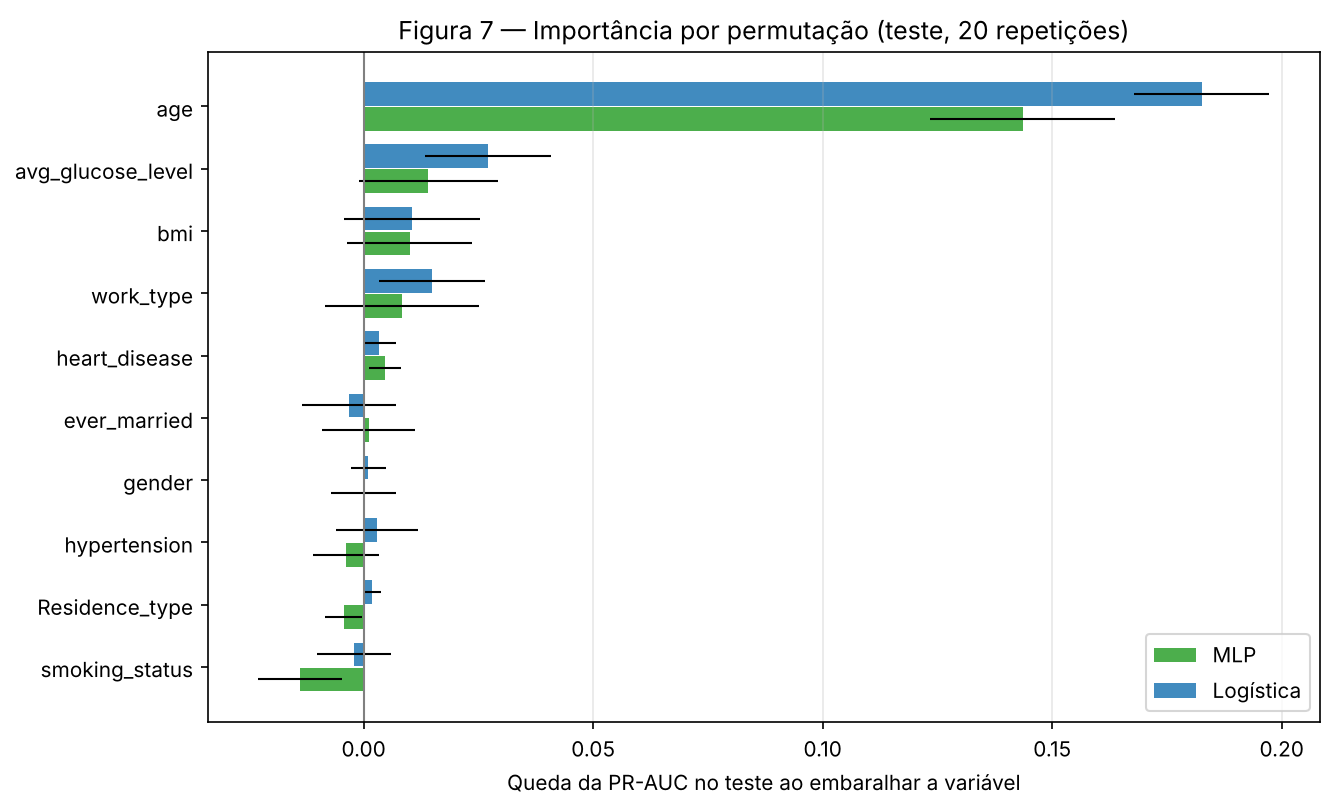

In [39]:
modelos_finais = {}
for s in SEMENTES_TESTE:
    m, _ = treinar_mlp(*dados, s, vies_saida=vies_inicial, **config_escolhida)
    modelos_finais[s] = m.eval()


def proba_rede(df_bruto, modelo):
    with torch.no_grad():
        x = torch.tensor(preprocess.transform(df_bruto), dtype=torch.float32)
        return torch.sigmoid(modelo(x).squeeze(1)).numpy()


for s, m in modelos_finais.items():
    assert np.allclose(proba_rede(X_test, m), probas_rede_teste[s]), "rede diferente da etapa 5"

N_REPETICOES = 20
rng = np.random.default_rng(0)
logistica = resultados["Logística"]["modelo"]
base_log = average_precision_score(y_teste, logistica.predict_proba(X_test)[:, 1])

quedas = []
for col in NUM + CAT:
    for r in range(N_REPETICOES):
        X_perm = X_test.copy()
        X_perm[col] = rng.permutation(X_perm[col].to_numpy())
        for s, m in modelos_finais.items():
            base = average_precision_score(y_teste, probas_rede_teste[s])
            quedas.append({"variável": col, "modelo": "MLP",
                           "queda": base - average_precision_score(y_teste, proba_rede(X_perm, m))})
        quedas.append({"variável": col, "modelo": "Logística",
                       "queda": base_log - average_precision_score(
                           y_teste, logistica.predict_proba(X_perm)[:, 1])})

tabela_perm = (pd.DataFrame(quedas).groupby(["variável", "modelo"])["queda"]
               .agg(["mean", "std"]).unstack("modelo"))
tabela_perm.columns = [f"{m}: queda {e}" for e, m in tabela_perm.columns]
tabela_perm = tabela_perm.sort_values("MLP: queda mean", ascending=False)
tabela_perm.columns = [c.replace("mean", "média").replace("std", "desvio") for c in tabela_perm.columns]
print("Tabela 6.3 — Importância por permutação no teste (queda da PR-AUC; 20 repetições)")
display(tabela_perm.round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))
try:
    ordem = tabela_perm.index[::-1]
    ypos = np.arange(len(ordem))
    for desloc, mod, cor in [(-0.2, "MLP", "tab:green"), (0.2, "Logística", "tab:blue")]:
        ax.barh(ypos + desloc, tabela_perm.loc[ordem, f"{mod}: queda média"], height=0.38,
                xerr=tabela_perm.loc[ordem, f"{mod}: queda desvio"], color=cor, alpha=0.85,
                label=mod, error_kw={"elinewidth": 1})
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_yticks(ypos, ordem)
    ax.set(xlabel="Queda da PR-AUC no teste ao embaralhar a variável",
           title="Figura 7 — Importância por permutação (teste, 20 repetições)")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIGURES / "fig07-permutacao.png", dpi=150, bbox_inches="tight")
    mostrar_e_fechar(fig)
finally:
    plt.close(fig)


**Leitura.** A idade domina: embaralhá-la derruba a PR-AUC da rede em 0,14 (0,18 na Logística), uma ordem de grandeza acima de qualquer outra variável. Em seguida vêm a glicose (0,014; 0,027 na Logística), o IMC com seu indicador de ausência (0,010) e o tipo de trabalho (0,008; 0,015 na Logística). Para todas as variáveis exceto a idade, o desvio entre repetições é do mesmo tamanho da queda média, então a importância delas não se distingue com segurança de zero. O tabagismo tem queda negativa (−0,014): embaralhá-lo melhora ligeiramente a rede, sinal de que ela aprendeu um pouco de ruído nessa variável. Rede e Logística dependem das mesmas variáveis, na mesma ordem principal, o que é coerente com o empate entre as duas.

**Comparação com o EDA.** A permutação **confirma** o principal achado do EDA: a idade é a variável com maior diferença entre as classes (Tabela 7 do EDA), e a glicose elevada e o IMC ausente também distinguiam subconjuntos com mais AVC. Ela **não confirma** a hipertensão e a doença cardíaca, que no EDA tinham proporções de AVC bem acima da média (Tabela 6 do EDA) e aqui quase não pesam. A explicação mais provável é a sobreposição com a idade, já apontada no EDA como possível confundimento (Tabela 6A): esses pacientes são, em sua maioria, idosos, e quando a idade está disponível, saber da hipertensão ou da doença cardíaca acrescenta pouca informação. O mesmo vale para o tipo de trabalho, cuja categoria `children` é um indicador de idade.

## Etapa 7 — Conclusão

### A rede valeu a pena?

Como modelo de previsão, não. No teste, a MLP obteve PR-AUC de 0,225 ± 0,012, abaixo da Regressão Logística (0,250), e não atingiu o critério de sucesso definido na etapa 0 (0,275). O bootstrap mostra que as duas são estatisticamente indistinguíveis neste teste (IC 95% da diferença: [−0,068; +0,005]), e a pequena vantagem da rede no ponto de operação (41 contra 40 AVCs identificados, cerca de 220 contra 238 alarmes falsos) é da ordem da variação entre sementes. Diante de um empate, a Logística é a escolha mais sensata: tem 25 parâmetros em vez de 209, é determinística, interpretável e suas probabilidades representam o risco observado.

Como investigação, valeu. O projeto mostrou de forma consistente que o limite está nos dados e não na rede: aumentar a largura, regularizar, tratar o desbalanceamento ou mudar a inicialização não alterou a PR-AUC além do ruído, e a importância por permutação mostrou que rede e Logística dependem praticamente só da idade. Com estas 10 variáveis, quase todo o sinal disponível é linear e já é capturado pela Logística.

### Limitações

- **Poucos casos de AVC.** São 249 no total, 159 no treino, 40 na validação e 50 no teste. Com esses números, a PR-AUC varia muito entre divisões e sementes, e diferenças de 0,01 a 0,02 não são confiáveis.
- **Uma única divisão de validação.** As escolhas das etapas 2 a 4 foram feitas numa só validação; uma validação cruzada repetida daria estimativas mais estáveis.
- **Sem informação temporal.** Não se sabe se as medidas foram coletadas antes do AVC, então o modelo não pode ser apresentado como previsão de um AVC futuro (limitação já apontada no EDA).
- **IMC ausente como sinal de risco.** A rede usa a ausência do IMC como indicador de AVC, e essa associação pode refletir o processo de coleta e não a saúde do paciente.
- **Variáveis limitadas.** Faltam fatores clínicos conhecidos de AVC, como pressão arterial medida, colesterol e arritmias; isso explica os AVCs em pacientes jovens sem nenhum fator registrado.
- **Origem dos dados.** O dataset é público e de fonte não documentada; não há garantia de que represente uma população real de pacientes.

### Quem seria afetado por um erro

- **Falsos negativos (≈ 1 em cada 5 AVCs).** Concentram-se em pacientes com menos de 65 anos e sem fatores de risco: na faixa abaixo de 45 anos, a rede detecta só 1 de 6 casos. É o erro mais grave, porque um AVC não identificado atrasa um atendimento urgente, e ele recai justamente sobre quem parece de baixo risco.
- **Falsos positivos (≈ 220 de 972 pacientes sem AVC).** Concentram-se nos idosos: 94% dos pacientes com 65 anos ou mais sem AVC são marcados. Para eles, o custo são exames adicionais, ansiedade e uso de recursos.
- **Uso responsável.** Um modelo assim só poderia servir como apoio de triagem, nunca como diagnóstico ou para negar atendimento. A decisão continua clínica, o desempenho deveria ser monitorado por faixa etária e o fato de o modelo quase nunca marcar pacientes jovens precisa ser conhecido por quem o usa.

### O que faríamos com mais tempo

- Repetir a seleção de modelo com validação cruzada estratificada, em vez de uma única divisão.
- Calibrar as probabilidades e avaliar limiares diferentes por faixa etária.
- Buscar mais dados e variáveis clínicas, que é o que limita o desempenho segundo esta análise.
- Investigar a origem dos registros sem IMC antes de usar esse indicador.
- Comparar com um modelo de boosting, que o enunciado sugere como baseline opcional.

### Resumo dos resultados

| # | Resumo | Valor |
|---|---|---|
| 1 | Dataset, tarefa, alvo e métrica principal | Stroke Prediction Dataset (Kaggle); classificação binária; alvo `stroke`; PR-AUC |
| 2 | Treino · validação · teste (linhas) | 3.270 · 818 · 1.022 (159 · 40 · 50 casos de AVC) |
| 3 | Melhor baseline e sua métrica no teste | Regressão Logística: PR-AUC 0,250 (ROC-AUC 0,843) |
| 4 | Rede escolhida: camadas × unidades, nº de parâmetros, regularização | 1 camada oculta × 8 unidades (24-8-1, ReLU); 209 parâmetros; sem regularização explícita, só parada antecipada |
| 5 | Otimizador, taxa, batch e época em que parou | AdamW, taxa 0,003, batch 32, weight decay 0; melhores épocas 8, 15 e 7 (sementes 0, 1 e 2), com parada após 10 épocas sem melhora |
| 6 | Métrica principal da rede no teste (média ± desvio, 3 sementes) | PR-AUC 0,225 ± 0,012 |
| 7 | Critério de sucesso atingido? | Não: meta 0,275 (Logística + 10%); diferença −0,025, IC 95% [−0,068; +0,005] |
| 8 | Subgrupo com o maior erro e o valor | Pacientes com 65 anos ou mais: erro total 0,773 (94% de alarme falso); o maior erro de falso negativo está abaixo de 45 anos (recall 0,17) |
